# Vibration of cylinders with four and eight stringers: Egle and Sewall (1968)

D. M. Egle and J. L. Sewall, *An analysis of free vibration of orthogonally stiffened cylindrical shells with stiffeners treated as discrete elements*, AIAA Journal 6(3) (1968) 518-526, https://doi.org/10.2514/3.4528.
J. L. Sewall and E. C. Naumann, *An experimental and analytical vibration study of thin cylindrical shells with and without longitudinal stiffeners*, NASA TN D-4705, September 1968 (NTRS 19680024266).

Egle and Sewall computed, with the stringers treated as discrete elements, the natural frequencies of two freely supported steel cylinders stiffened by four and by eight equally spaced internal stringers of open profile (their Table 1, p. 522), and plotted them against the circumferential wave number in their Figs. 3 and 4 (p. 523). For the four-stringer shell they tabulated the frequencies of the modes symmetric and antisymmetric about the plane of a stringer and of the unstiffened shell (Table 3, p. 524). Sewall and Naumann analysed the eight-stringer shell with two analyses that average the stringers over the shell surface (Fig. 12, report p. 52, and text p. 20).

This notebook models the two stiffened shells and the unstiffened one with `panels`, each stringer assembled from plates, and compares the frequencies with every analysis of these sources: the frequencies of Table 3, the theory curves of Figs. 3 and 4 and both averaged analyses of Fig. 12. The same comparison for the shell with 60 stringers, the externally stiffened shell (ES) of Sewall and Naumann, which is the 60-stringer shell of Egle and Sewall (Table 1, Ref. 14), is in the notebook [sewall1968_blade_cylinder_vibration](sewall1968_blade_cylinder_vibration.ipynb).

In [1]:
%matplotlib inline

import csv
import time

import numpy as np
import matplotlib.pyplot as plt
from IPython.display import Markdown, display

import few_stringer_cylinder_utils as fu
from few_stringer_cylinder_utils import IN, PSI, LBS2IN4, LBF


def pct(value, ref):
    return 100*(value - ref)/ref


def markdown_table(header, rows):
    out = ['| ' + ' | '.join(header) + ' |', '|' + '---|'*len(header)]
    out += ['| ' + ' | '.join(str(c) for c in row) + ' |' for row in rows]
    return Markdown('\n'.join(out))


def stats(d):
    d = np.asarray(d)
    return ['%d' % len(d), '%+.1f%%' % d.mean(), '%.1f%%' % np.abs(d).mean(),
            '%+.1f%%' % d.min(), '%+.1f%%' % d.max()]

STATS = ['values', 'mean', 'mean abs.', 'min.', 'max.']

## The shells

Table 1 of Egle and Sewall (p. 522) gives the properties of the shells with four and eight stringers ("open profile stringers"): radius $R$, length $a$, skin thickness $h$, Young's modulus $E$, density $\rho$, Poisson's ratio $\nu$ and, for each stringer, the area $A_s$, the coordinate $\bar{z}_s$ of its centroid (negative: inside the shell), the torsional stiffness $(GJ)_s$, the radius of gyration $d_s'$ and the polar radius of gyration $p_s'$, with $D_x/D = D_y/D = 1$ (no transverse stiffening by the stringers). Sewall and Naumann give the same shell, rounded, in Fig. 12 ($L$ = 38.85 in, $R$ = 7.65 in, $h$ = 0.0183 in) and describe it on p. 20: "made of 0.0183-inch-thick (0.464-mm) sheet steel" with "four and eight internal stringers of hat-shaped cross section". The material is taken as isotropic, $G = E/(2(1 + \nu))$ (not given in either paper).

In [2]:
# Egle and Sewall (1968), Table 1 (p. 522), 4 and 8 stringer case; in, psi, lb-s^2/in^4, in^2, lb-in^2
TABLE_1 = dict(R=7.657, a=38.85, h=1.826e-2, E=29.0e6, rho=7.34e-4, nu=0.30,
               d=0.2576, p=0.2750, A=1.627e-2, z=-0.2082, GJ=11.31)
R, L, H = TABLE_1['R']*IN, TABLE_1['a']*IN, TABLE_1['h']*IN
E, NU, RHO = TABLE_1['E']*PSI, TABLE_1['nu'], TABLE_1['rho']*LBS2IN4
G_PSI = TABLE_1['E']/(2*(1 + TABLE_1['nu']))
print('1 in = %.4f m, 1 psi = %.3f Pa, 1 lb-s^2/in^4 = %.1f kg/m^3' % (IN, PSI, LBS2IN4))
print('R = %.3f in = %.1f mm, a = %.2f in = %.1f mm, h = %.5f in = %.4f mm'
      % (TABLE_1['R'], R*1e3, TABLE_1['a'], L*1e3, TABLE_1['h'], H*1e3))
print('E = %.1e psi = %.1f GPa, rho = %.2e lb-s^2/in^4 = %.0f kg/m^3, G = E/(2(1 + nu)) = %.3e psi'
      % (TABLE_1['E'], E/1e9, TABLE_1['rho'], RHO, G_PSI))

1 in = 0.0254 m, 1 psi = 6894.757 Pa, 1 lb-s^2/in^4 = 10686895.2 kg/m^3
R = 7.657 in = 194.5 mm, a = 38.85 in = 986.8 mm, h = 0.01826 in = 0.4638 mm
E = 2.9e+07 psi = 199.9 GPa, rho = 7.34e-04 lb-s^2/in^4 = 7844 kg/m^3, G = E/(2(1 + nu)) = 1.115e+07 psi


### The stringer section

The stringer is drawn in the detail of Fig. 12 of Sewall and Naumann (dimensions in in and mm): wall thickness 0.014 in (0.35 mm), base 0.197 in (5.00 mm) wide over the outer faces of the webs, height 0.394 in (10.00 mm), lips 0.098 in (2.50 mm) at the free edges of the webs, pointing away from the channel. The dimension line of the height runs from the inner face of the base to the extension line of the top of the lips, and that of the lips from the outer face of the web to the tip of the lip (read on the drawing, enlarged). The stringer is a hat (open channel with lips) whose base lies on the skin.

**Plates of the model.** Every wall is a plate of thickness $t$ = 0.014 in along its midline (helper `fu.channel_midlines`): the base, between the midlines of the webs, $0.197 - t$ = 0.183 in; the webs, from the midline of the base to the midline of the lips, $0.394 + t - t$ = 0.394 in; the lips, from the midline of the web to the tip, $0.098 + t/2$ = 0.105 in. The webs and lips are flat plates (`plate_clpt_gl`, see the notebook of the 60-stringer case for this choice). The base is treated in two ways:

- **base as a plate** (the reference model): the base is a curved panel (`cylshell_clpt_sanders`) of thickness $t$ covering a strip of skin of the same width, bonded to it over its area with the skin-base connection `'SB'` (lower face of the skin to the upper face of the base); the webs stand on the edges of the base, at the middle surface of the base, $h/2 + t/2$ inside the middle surface of the skin;
- **base in the skin laminate** (variant): the strip of skin under the stringer has the thickness $h + t$, with the offset $-t/2$ that keeps its reference surface at the middle surface of the skin, and the webs, connected at that reference surface, are $h/2 + t/2$ longer, overlapping the strip.

The table compares the section of the plates (rectangles of thickness $t$ along the midlines, overlapping at the corners) with Table 1. $\bar{z}$ is the distance of the centroid from the middle surface of the skin. The radius of gyration $d'$ enters the stringer strain energy of Egle and Sewall, Eq. (5), as $E A (u_{,x}^2 - 2 \bar{z} u_{,x} w_{,xx} + d'^2 w_{,xx}^2)$, which is the exact bending energy of the section only with $d'^2 A = \int z^2 dA$ about the middle surface of the skin, so $d'$ is computed so; the radius of gyration about the centroid would be 0.15 in for Table 1 ($\sqrt{d'^2 - \bar{z}^2}$, derived). The polar radius $p'$ is taken about the same line, $p'^2 A = \int (y^2 + z^2) dA$. The torsion constant of the open thin-walled section is $J = \sum b t^3/3$ over the midline lengths $b$. The second reading of the drawing, the height 0.394 in measured from the outer face of the base (the face on the skin), is listed for comparison: it matches Table 1 better in area and centroid, but contradicts the dimension line, and its effect on the frequencies is shown in the sensitivity study below.

**Suspected error in Table 1 of Egle and Sewall.** The centroid $\bar{z}_s$ = 0.2082 in of Table 1 is probably measured from the inner surface of the skin, not from its middle surface, from which $z$ is measured in their Eqs. (1) and (5). The evidence: the area, $d'$ and $p'$ of Table 1 match the drawn section about the middle surface of the skin within 1.6 to 2.1 % (table below), while its centroid, 0.2176 in from the middle surface, is 0.2176 $- h/2$ = 0.2085 in from the inner surface, within 0.15 % of Table 1; the difference is $h/2$ = 0.0091 in (4.4 %). This is a suspicion, not a fact: the section of Table 1 may also differ from the drawing. Its effect on their analysis is small (recomputed below, 0.2 percentage points or less on the mean differences with Table 3).

In [3]:
SEC = fu.channel_midlines(0.014*IN, 0.197*IN, 0.394*IN, 0.098*IN)
SEC_OUTER = fu.channel_midlines(0.014*IN, 0.197*IN, 0.394*IN, 0.098*IN, height_from='base_outer')
print('midlines, in: base %.3f, web %.3f, lip %.3f' % (SEC['base']/IN, SEC['web']/IN, SEC['lip']/IN))
rows = []
ref = TABLE_1
rows.append(['Table 1 (p. 522)', '%.4e' % ref['A'], '%.4f' % abs(ref['z']), '%.4f' % ref['d'],
             '%.4f' % ref['p'], '%.2f' % ref['GJ']])
for label, sec, base in (('drawing, base as a plate (reference)', SEC, 'plate'),
                         ('drawing, base in the skin laminate', SEC, 'laminate'),
                         ('height from the outer face of the base, base as a plate', SEC_OUTER, 'plate')):
    sp = fu.section_properties(sec, H, base=base)
    A, z, d, p = sp['A']/IN**2, sp['z']/IN, sp['d']/IN, sp['p']/IN
    GJ = G_PSI*sp['J']/IN**4
    rows.append([label, '%.4e (%+.1f%%)' % (A, pct(A, ref['A'])), '%.4f (%+.1f%%)' % (z, pct(z, abs(ref['z']))),
                 '%.4f (%+.1f%%)' % (d, pct(d, ref['d'])), '%.4f (%+.1f%%)' % (p, pct(p, ref['p'])),
                 '%.2f (%+.1f%%)' % (GJ, pct(GJ, ref['GJ']))])
display(markdown_table(['section', 'A, in^2', 'centroid inside the skin middle surface, in', "d', in",
                        "p', in", 'GJ, lb-in^2'], rows))

midlines, in: base 0.183, web 0.394, lip 0.105


| section | A, in^2 | centroid inside the skin middle surface, in | d', in | p', in | GJ, lb-in^2 |
|---|---|---|---|---|---|
| Table 1 (p. 522) | 1.6270e-02 | 0.2082 | 0.2576 | 0.2750 | 11.31 |
| drawing, base as a plate (reference) | 1.6534e-02 (+1.6%) | 0.2176 (+4.5%) | 0.2625 (+1.9%) | 0.2807 (+2.1%) | 12.05 (+6.5%) |
| drawing, base in the skin laminate | 1.6986e-02 (+4.4%) | 0.2121 (+1.9%) | 0.2590 (+0.5%) | 0.2773 (+0.8%) | 12.38 (+9.4%) |
| height from the outer face of the base, base as a plate | 1.6142e-02 (-0.8%) | 0.2106 (+1.1%) | 0.2541 (-1.4%) | 0.2729 (-0.8%) | 11.76 (+4.0%) |

The figure shows the section of the reference model to scale (plates as midlines with their thickness) on the skin, and the cross-sections of the two shells.

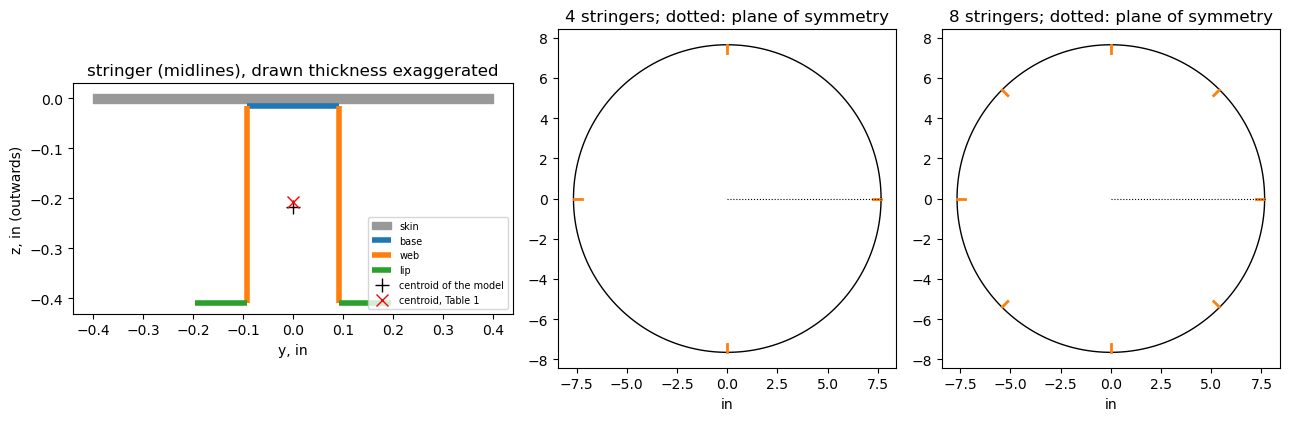

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(13, 4), gridspec_kw=dict(width_ratios=[1.3, 1, 1]))
ax = axes[0]
t, h = SEC['t']/IN, TABLE_1['h']
bw, web, lip = SEC['base']/IN, SEC['web']/IN, SEC['lip']/IN
zb = h/2 + t/2
ax.fill_between([-0.4, 0.4], -h/2, h/2, color='0.6', label='skin')
ax.plot([-bw/2, bw/2], [-zb, -zb], 'C0-', lw=4, solid_capstyle='butt', label='base')
for s in (-1, 1):
    ax.plot([s*bw/2, s*bw/2], [-zb, -zb - web], 'C1-', lw=4, solid_capstyle='butt',
            label='web' if s < 0 else None)
    ax.plot([s*bw/2, s*(bw/2 + lip)], [-zb - web, -zb - web], 'C2-', lw=4, solid_capstyle='butt',
            label='lip' if s < 0 else None)
sp = fu.section_properties(SEC, H)
ax.plot(0, -sp['z']/IN, 'k+', ms=10, label='centroid of the model')
ax.plot(0, TABLE_1['z'], 'rx', ms=8, label='centroid, Table 1')
ax.set_aspect('equal')
ax.set_xlabel('y, in')
ax.set_ylabel('z, in (outwards)')
ax.set_title('stringer (midlines), drawn thickness exaggerated')
ax.legend(fontsize=7, loc='lower right')
for ax, ns in zip(axes[1:], (4, 8)):
    th = np.linspace(0, 2*np.pi, 400)
    ax.plot(TABLE_1['R']*np.cos(th), TABLE_1['R']*np.sin(th), 'k-', lw=1)
    for k in range(ns):
        thk = 2*np.pi*k/ns
        r1, r2 = TABLE_1['R'] - zb, TABLE_1['R'] - zb - web
        ax.plot([r1*np.cos(thk), r2*np.cos(thk)], [r1*np.sin(thk), r2*np.sin(thk)], 'C1-', lw=2)
    ax.plot([0, TABLE_1['R']], [0, 0], 'k:', lw=0.8)
    ax.set_aspect('equal')
    ax.set_title('%d stringers; dotted: plane of symmetry' % ns)
    ax.set_xlabel('in')
plt.tight_layout()
plt.show()

## Model

**Assembly.** The whole cylinder is modelled with `panels.multidomain.MultiDomain` (helper `fu.build_cylinder`): the skin is divided into a strip under each stringer base and the bays between the strips, curved panels of the Sanders-Koiter model (`cylshell_clpt_sanders`) connected with `'SSycte'`; under each stringer the base (`cylshell_clpt_sanders`) is bonded to the strip with `'SB'`, the two webs stand on its edges (`'BFycte'`, the flange normal to its base) and each lip is connected to the free edge of its web (`'BFycte'`, normal to the web, pointing away from the channel). All connections are imposed exactly with `conn_method='null-space'`. The Legendre-based (Bardell) approximation functions of `panels` are those of Castro and Donadon (2017, https://doi.org/10.1016/j.compstruct.2016.10.026). A sector model is not used: the planes through a stringer are planes of symmetry of the structure, but a stringer on a plane of symmetry would have to be cut in half, and the antisymmetric modes would need the other boundary conditions; the whole circumference, with both families in one eigenvalue problem, is simpler and checks the classification.

**Ends.** Egle and Sewall use the "pinned-end" beam functions, for which $v = w = 0$ at the shell and stringer ends, the axial force and bending moment vanishing, and call the condition "simply supported without axial constraint (or freely supported)" for the shell and the stringers (p. 520). The model has at both ends $v = w = 0$, $u$ free, for the skin and the base, and for the webs and lips their two displacements in the plane of the cross-section zero ($v = w = 0$ of each plate), $u$ free (`fu.FREELY_SUPPORTED`). Sewall and Naumann call the eight-stringer shell "simply supported" (Fig. 12).

**Symmetric and antisymmetric modes.** The stringers are equally spaced, the first one at $\theta = 0$ (the $x$-$z$ plane of Egle and Sewall). Egle and Sewall call symmetric (antisymmetric) the modes whose normal displacement is symmetric (antisymmetric) about this plane, the unprimed (primed) coefficients of their series, $\cos n\theta$ ($\sin n\theta$) terms of $w$ (Eq. (9), p. 520). With the stringers distributed symmetrically the two families uncouple, and with equally spaced stringers a circumferential harmonic $n$ is coupled only with the harmonics $j$ for which $j + n$ or $|j - n|$ is a multiple of the number of stringers $L$ (their Eq. (13), p. 522). For four stringers the two frequencies are equal for odd $n$ (p. 523): the eigensolver then returns any combination of the two modes, and `fu.frequencies` rotates each pair of equal frequencies into a symmetric and an antisymmetric mode.

**Classification** (`fu.classify`), as Egle and Sewall do (p. 522): the normal displacement of the skin, $w(x, \theta)$, is expanded in $\cos n\theta$ and $\sin n\theta$ at 41 sections along $x$ (`fu.harmonics`); the mode is identified with the harmonic $n$ of largest amplitude, its symmetry by the fraction of the cosine terms (1 symmetric, 0 antisymmetric), and $m$ by the sine $\sin(m \pi x/a)$ that best represents the dominant harmonic along $x$. The ratio of the second largest to the largest amplitude is the coupling strength of Egle and Sewall (p. 524). For each $(m, n)$ and symmetry the lowest frequency is compared.

## The unstiffened shell: closed form

Without stringers, the energies of Egle and Sewall reduce to those of the Donnell shell (their Eqs. (1), (2) and (6), with $D_x = D_y = D$), and the freely supported shell has the exact modes $u = A \cos(m\pi x/a) \cos n\theta$, $v = B \sin(m\pi x/a) \sin n\theta$, $w = C \sin(m\pi x/a) \cos n\theta$. With $\lambda = m\pi R/a$, $k = h^2/(12 R^2)$ and their frequency parameter $\Delta = (1 - \nu^2)\rho R^2 \omega^2/E$, $\Delta$ is the smallest eigenvalue of a symmetric 3 by 3 matrix (`fu.donnell_ss`); neglecting the in-surface inertia, as Egle and Sewall do for their numerical results ("the in-surface inertias are neglected", p. 522), it becomes

$$\Delta = \frac{(1 - \nu^2)\lambda^4}{(\lambda^2 + n^2)^2} + k (\lambda^2 + n^2)^2 .$$

The table compares both with column c of Table 3 (p. 524, unstiffened). Column c is reproduced by the formula without in-surface inertia to the three significant figures of the table, which confirms both the data and the simplification of Egle and Sewall: the in-surface inertia lowers the frequency by 4.6 to 5.6 % at $n = 3$, by about 3 % at $n = 4$, 2 % at $n = 5$ and by 1 % or less for $n \ge 8$ (table below).

In [5]:
TABLE_3 = {}
with open('results/egle1968_few_stringers.csv') as f:
    rows_csv = list(csv.DictReader(line for line in f if not line.startswith('#')))
for r in rows_csv:
    if r['source'] == 'table3':
        col = {'sym': 'a', 'antisym': 'b', 'none': 'c'}[r['symmetry']]
        TABLE_3[(col, int(r['m']), int(r['n']))] = float(r['f_Hz'])
print('%d values of Table 3' % len(TABLE_3))
rows = []
d_no, d_with = [], []
for n in range(3, 13):
    row = ['%d' % n]
    for m in range(1, 5):
        ref = TABLE_3[('c', m, n)]
        f0 = fu.donnell_ss(R, H, L, E, NU, RHO, m, n, inplane_inertia=False)
        f1 = fu.donnell_ss(R, H, L, E, NU, RHO, m, n)
        d_no.append(pct(f0, ref))
        d_with.append(pct(f1, ref))
        row += ['%g' % ref, '%.1f (%+.1f%%)' % (f0, pct(f0, ref)), '%.1f (%+.1f%%)' % (f1, pct(f1, ref))]
    rows.append(row)
display(markdown_table(['n'] + ['m=%d %s' % (m, s) for m in range(1, 5)
                                for s in ('Table 3 c', 'no in-surface inertia', 'with inertia')], rows))
display(markdown_table(['Donnell, against Table 3 c'] + STATS,
                       [['without in-surface inertia'] + stats(d_no), ['with in-surface inertia'] + stats(d_with)]))

120 values of Table 3


| n | m=1 Table 3 c | m=1 no in-surface inertia | m=1 with inertia | m=2 Table 3 c | m=2 no in-surface inertia | m=2 with inertia | m=3 Table 3 c | m=3 no in-surface inertia | m=3 with inertia | m=4 Table 3 c | m=4 no in-surface inertia | m=4 with inertia |
|---|---|---|---|---|---|---|---|---|---|---|---|---|
| 3 | 171 | 171.1 (+0.1%) | 161.9 (-5.3%) | 602 | 602.3 (+0.1%) | 568.1 (-5.6%) | 1146 | 1145.6 (-0.0%) | 1083.6 (-5.4%) | 1675 | 1675.2 (+0.0%) | 1597.5 (-4.6%) |
| 4 | 108 | 108.3 (+0.3%) | 105.0 (-2.8%) | 365 | 365.1 (+0.0%) | 353.2 (-3.2%) | 735 | 735.2 (+0.0%) | 710.9 (-3.3%) | 1147 | 1146.9 (-0.0%) | 1110.9 (-3.2%) |
| 5 | 98.1 | 98.1 (-0.0%) | 96.1 (-2.0%) | 251 | 251.6 (+0.2%) | 246.3 (-1.9%) | 508 | 508.2 (+0.0%) | 497.3 (-2.1%) | 819 | 819.3 (+0.0%) | 801.7 (-2.1%) |
| 6 | 117 | 116.9 (-0.1%) | 115.3 (-1.5%) | 203 | 202.5 (-0.2%) | 199.6 (-1.7%) | 380 | 380.0 (+0.0%) | 374.4 (-1.5%) | 615 | 614.5 (-0.1%) | 605.2 (-1.6%) |
| 7 | 151 | 150.7 (-0.2%) | 149.2 (-1.2%) | 196 | 196.0 (+0.0%) | 194.0 (-1.0%) | 314 | 313.6 (-0.1%) | 310.2 (-1.2%) | 488 | 488.2 (+0.0%) | 482.8 (-1.1%) |
| 8 | 194 | 193.5 (-0.2%) | 192.0 (-1.0%) | 218 | 218.0 (+0.0%) | 216.3 (-0.8%) | 292 | 291.7 (-0.1%) | 289.3 (-0.9%) | 418 | 417.5 (-0.1%) | 414.0 (-1.0%) |
| 9 | 243 | 243.4 (+0.2%) | 241.9 (-0.4%) | 258 | 257.8 (-0.1%) | 256.2 (-0.7%) | 303 | 303.1 (+0.0%) | 301.2 (-0.6%) | 390 | 390.0 (-0.0%) | 387.4 (-0.7%) |
| 10 | 300 | 299.7 (-0.1%) | 298.2 (-0.6%) | 309 | 309.1 (+0.0%) | 307.5 (-0.5%) | 338 | 337.8 (-0.1%) | 336.1 (-0.6%) | 396 | 396.4 (+0.1%) | 394.3 (-0.4%) |
| 11 | 362 | 362.1 (+0.0%) | 360.7 (-0.4%) | 369 | 369.0 (-0.0%) | 367.4 (-0.4%) | 388 | 388.3 (+0.1%) | 386.7 (-0.3%) | 428 | 428.3 (+0.1%) | 426.4 (-0.4%) |
| 12 | 431 | 430.6 (-0.1%) | 429.1 (-0.4%) | 436 | 436.1 (+0.0%) | 434.6 (-0.3%) | 450 | 450.1 (+0.0%) | 448.5 (-0.3%) | 478 | 478.4 (+0.1%) | 476.7 (-0.3%) |

| Donnell, against Table 3 c | values | mean | mean abs. | min. | max. |
|---|---|---|---|---|---|
| without in-surface inertia | 40 | -0.0% | 0.1% | -0.2% | +0.3% |
| with in-surface inertia | 40 | -1.6% | 1.6% | -5.6% | -0.3% |

## Convergence

The number of terms is increased in four steps, $m_x$ along $x$ (the same in every panel, so that the connections along $x$ are exact), $n_y$ across a bay of the skin, $n_s$ across a strip and its base, $n_w$ across a web and $n_l$ across a lip (at least 4 across the plates connected along an edge, see `MultiDomain.check_conn_terms`). The table gives the largest relative change, from the previous step, of the frequencies compared below: $m$ = 1 to 4, $n$ = 2 to 13, both symmetries. The lowest eigenpairs are computed, their number increased until the highest computed frequency exceeds `FMAX` by 5 %, and the modes up to `FMAX` = 1800 Hz are kept (above the highest frequency of Table 3, 1675 Hz). The columns residual and backward error give the largest relative residual $\|(oldsymbol{K} - \omega^2 oldsymbol{M}) oldsymbol{\phi}\| / \|oldsymbol{K} oldsymbol{\phi}\|$ and the largest backward error of the kept modes (see `fu.frequencies`). The last step is used in the comparisons.

In [6]:
LEVELS = {4: [(10, 16, 4, 4, 4), (12, 20, 5, 5, 4), (14, 24, 6, 6, 5), (16, 28, 6, 6, 5)],
          8: [(10, 12, 4, 4, 4), (12, 16, 5, 5, 4), (14, 20, 6, 6, 5), (16, 24, 6, 6, 5)]}
LEVELS['U'] = LEVELS[4]
NUM_EIGVALUES = {4: 650, 8: 650, 'U': 650}
FMAX = 1800.
COMPARED = [(m, n) for m in range(1, 5) for n in range(2, 14)]


def run(shell, level, sec=SEC, base='plate', keep_vectors=False, **kw):
    mx, ny, ns, nw, nl = level
    nstiff = 4 if shell == 'U' else shell
    md, skin, th0 = fu.build_cylinder(R, H, L, E, NU, RHO, nstiff, sec, base=base,
                                      stiffened=shell != 'U', mx=mx, ny=ny, ns=ns, nw=nw, nl=nl)
    k = NUM_EIGVALUES[shell]
    while True:
        modes, x, dt, rres, berr, fhigh = fu.frequencies(md, skin, R, L, th0, num_eigvalues=k,
                                                         fmax=FMAX, **kw)
        if fhigh > 1.05*FMAX:
            break
        k = int(1.3*k)
    if not keep_vectors:
        for mode in modes:
            for key in ('a', 'b', 'c'):
                mode.pop(key)
    low = {s: fu.lowest(modes, s) for s in ('sym', 'antisym')}
    return dict(md=md, skin=skin, th0=th0, modes=modes, x=x, dt=dt, rres=rres, berr=berr, fhigh=fhigh,
                low=low, k=k)


def change(new, old):
    out = 0.
    for s in ('sym', 'antisym'):
        for mn in COMPARED:
            if mn in new[s] and mn in old[s]:
                out = max(out, abs(pct(new[s][mn]['f'], old[s][mn]['f'])))
    return out


RES = {}
rows = []
for shell in (4, 8, 'U'):
    prev = None
    for i, level in enumerate(LEVELS[shell]):
        res = run(shell, level, keep_vectors=i == len(LEVELS[shell]) - 1)
        RES[(shell, i)] = res
        ch = '-' if prev is None else '%.2f%%' % change(res['low'], prev['low'])
        rows.append([shell if shell == 'U' else '%d stringers' % shell, '%d, %d, %d, %d, %d' % level,
                     res['md'].get_size(), res['k'], len(res['modes']), '%.0f' % res['fhigh'],
                     '%.0f' % res['dt'], '%.0e' % res['rres'], '%.0e' % res['berr'], ch])
        prev = res
display(markdown_table(['shell', 'm_x, n_y, n_s, n_w, n_l', 'dofs before the connections', 'eigenpairs',
                        'modes kept', 'highest computed f, Hz', 'time, s', 'residual', 'backward error',
                        'max. change'], rows))
FINAL = 3
LOW = {shell: RES[(shell, FINAL)]['low'] for shell in (4, 8, 'U')}

| shell | m_x, n_y, n_s, n_w, n_l | dofs before the connections | eigenpairs | modes kept | highest computed f, Hz | time, s | residual | backward error | max. change |
|---|---|---|---|---|---|---|---|---|---|
| 4 stringers | 10, 16, 4, 4, 4 | 4800 | 650 | 284 | 14034 | 20 | 1e-02 | 2e-14 | - |
| 4 stringers | 12, 20, 5, 5, 4 | 6912 | 650 | 366 | 4009 | 32 | 1e-01 | 8e-15 | 7.34% |
| 4 stringers | 14, 24, 6, 6, 5 | 9744 | 650 | 418 | 2663 | 47 | 2e-01 | 3e-13 | 1.30% |
| 4 stringers | 16, 28, 6, 6, 5 | 11904 | 650 | 468 | 2388 | 64 | 6e-01 | 5e-13 | 0.03% |
| 8 stringers | 10, 12, 4, 4, 4 | 8640 | 650 | 344 | 4707 | 44 | 2e-02 | 9e-14 | - |
| 8 stringers | 12, 16, 5, 5, 4 | 12672 | 650 | 396 | 2798 | 69 | 3e-02 | 7e-14 | 0.54% |
| 8 stringers | 14, 20, 6, 6, 5 | 18144 | 650 | 435 | 2381 | 103 | 6e-02 | 3e-13 | 0.00% |
| 8 stringers | 16, 24, 6, 6, 5 | 22272 | 650 | 483 | 2202 | 131 | 1e-02 | 9e-14 | 0.00% |
| U | 10, 16, 4, 4, 4 | 2400 | 650 | 283 | 22561 | 17 | 1e-01 | 9e-12 | - |
| U | 12, 20, 5, 5, 4 | 3600 | 650 | 357 | 6350 | 26 | 8e-02 | 3e-11 | 0.09% |
| U | 14, 24, 6, 6, 5 | 5040 | 650 | 407 | 2994 | 36 | 2e-01 | 4e-11 | 0.00% |
| U | 16, 28, 6, 6, 5 | 6528 | 650 | 457 | 2684 | 44 | 4e-02 | 8e-12 | 0.00% |

## Four stringers: Table 3 of Egle and Sewall

Frequencies of the symmetric (Table 3 a), antisymmetric (b) and unstiffened (c) shells, Table 3 (p. 524, typed from the page image and checked against its text layer, `results/egle1968_few_stringers.csv`), against `panels` with the same $(m, n)$ and symmetry. The unstiffened model is the same assembly without the stringers.

In [7]:
def table3_comparison(low4, lowU, label):
    rows = []
    D = {'a': [], 'b': [], 'c': []}
    for m in range(1, 5):
        for n in range(3, 13):
            row = ['%d, %d' % (m, n)]
            for col, low in (('a', low4['sym']), ('b', low4['antisym']), ('c', lowU['sym'])):
                ref = TABLE_3[(col, m, n)]
                if (m, n) in low:
                    f = low[(m, n)]['f']
                    D[col].append(pct(f, ref))
                    row += ['%g' % ref, '%.1f (%+.1f%%)' % (f, pct(f, ref))]
                else:
                    row += ['%g' % ref, 'not found']
            rows.append(row)
    display(markdown_table(['m, n', 'a: sym., Table 3', 'panels', 'b: antisym., Table 3', 'panels',
                            'c: unstiffened, Table 3', 'panels'], rows))
    summary = [['%s, %s' % (label, col)] + stats(D[col]) for col in ('a', 'b', 'c')]
    display(markdown_table(['Table 3 column'] + STATS, summary))
    return D


D_T3 = table3_comparison(LOW[4], LOW['U'], 'panels')

| m, n | a: sym., Table 3 | panels | b: antisym., Table 3 | panels | c: unstiffened, Table 3 | panels |
|---|---|---|---|---|---|---|
| 1, 3 | 169 | 160.0 (-5.3%) | 169 | 160.0 (-5.3%) | 171 | 161.4 (-5.6%) |
| 1, 4 | 103 | 99.0 (-3.9%) | 108 | 102.9 (-4.7%) | 108 | 103.7 (-4.0%) |
| 1, 5 | 94.7 | 91.1 (-3.8%) | 94.7 | 91.1 (-3.8%) | 98.1 | 93.9 (-4.3%) |
| 1, 6 | 109 | 106.9 (-1.9%) | 116 | 111.7 (-3.7%) | 117 | 112.5 (-3.8%) |
| 1, 7 | 145 | 140.8 (-2.9%) | 145 | 140.8 (-2.9%) | 151 | 146.3 (-3.1%) |
| 1, 8 | 183 | 181.5 (-0.8%) | 192 | 187.1 (-2.5%) | 194 | 189.1 (-2.5%) |
| 1, 9 | 236 | 232.7 (-1.4%) | 236 | 232.7 (-1.4%) | 243 | 239.0 (-1.7%) |
| 1, 10 | 278 | 277.0 (-0.4%) | 297 | 290.5 (-2.2%) | 300 | 295.2 (-1.6%) |
| 1, 11 | 350 | 348.2 (-0.5%) | 350 | 348.2 (-0.5%) | 362 | 357.7 (-1.2%) |
| 1, 12 | 408 | 410.5 (+0.6%) | 425 | 418.2 (-1.6%) | 431 | 426.1 (-1.1%) |
| 2, 3 | 591 | 556.1 (-5.9%) | 591 | 556.1 (-5.9%) | 602 | 567.9 (-5.7%) |
| 2, 4 | 346 | 335.8 (-2.9%) | 365 | 350.1 (-4.1%) | 365 | 352.8 (-3.3%) |
| 2, 5 | 241 | 236.0 (-2.1%) | 241 | 236.0 (-2.1%) | 251 | 245.4 (-2.2%) |
| 2, 6 | 194 | 190.6 (-1.7%) | 202 | 196.8 (-2.6%) | 203 | 198.0 (-2.5%) |
| 2, 7 | 191 | 188.2 (-1.5%) | 191 | 188.2 (-1.5%) | 196 | 191.6 (-2.2%) |
| 2, 8 | 209 | 207.6 (-0.7%) | 217 | 211.9 (-2.4%) | 218 | 213.6 (-2.0%) |
| 2, 9 | 256 | 252.4 (-1.4%) | 256 | 252.4 (-1.4%) | 258 | 253.3 (-1.8%) |
| 2, 10 | 297 | 296.4 (-0.2%) | 306 | 300.9 (-1.7%) | 309 | 304.6 (-1.4%) |
| 2, 11 | 358 | 355.8 (-0.6%) | 358 | 355.8 (-0.6%) | 369 | 364.5 (-1.2%) |
| 2, 12 | 424 | 424.1 (+0.0%) | 430 | 424.4 (-1.3%) | 436 | 431.6 (-1.0%) |
| 3, 3 | 1137 | 1089.6 (-4.2%) | 1137 | 1089.6 (-4.2%) | 1146 | 1083.5 (-5.5%) |
| 3, 4 | 688 | 671.5 (-2.4%) | 733 | 703.3 (-4.1%) | 735 | 710.6 (-3.3%) |
| 3, 5 | 490 | 480.3 (-2.0%) | 490 | 480.3 (-2.0%) | 508 | 496.7 (-2.2%) |
| 3, 6 | 371 | 364.9 (-1.7%) | 379 | 371.6 (-2.0%) | 380 | 373.4 (-1.7%) |
| 3, 7 | 313 | 308.7 (-1.4%) | 313 | 308.7 (-1.4%) | 314 | 308.6 (-1.7%) |
| 3, 8 | 297 | 293.2 (-1.3%) | 290 | 285.7 (-1.5%) | 292 | 287.2 (-1.6%) |
| 3, 9 | 304 | 300.6 (-1.1%) | 304 | 300.6 (-1.1%) | 303 | 298.6 (-1.4%) |
| 3, 10 | 341 | 339.5 (-0.4%) | 334 | 330.2 (-1.1%) | 338 | 333.3 (-1.4%) |
| 3, 11 | 386 | 383.2 (-0.7%) | 386 | 383.2 (-0.7%) | 388 | 383.8 (-1.1%) |
| 3, 12 | 443 | 443.4 (+0.1%) | 444 | 438.9 (-1.1%) | 450 | 445.5 (-1.0%) |
| 4, 3 | 1643 | 1594.0 (-3.0%) | 1643 | 1594.0 (-3.0%) | 1675 | 1597.5 (-4.6%) |
| 4, 4 | 1089 | 1057.5 (-2.9%) | 1144 | 1092.4 (-4.5%) | 1147 | 1110.7 (-3.2%) |
| 4, 5 | 801 | 781.6 (-2.4%) | 801 | 781.6 (-2.4%) | 819 | 801.4 (-2.2%) |
| 4, 6 | 604 | 594.9 (-1.5%) | 615 | 607.2 (-1.3%) | 615 | 604.5 (-1.7%) |
| 4, 7 | 491 | 484.7 (-1.3%) | 491 | 484.7 (-1.3%) | 488 | 481.7 (-1.3%) |
| 4, 8 | 432 | 426.5 (-1.3%) | 415 | 410.6 (-1.1%) | 418 | 412.4 (-1.3%) |
| 4, 9 | 396 | 392.8 (-0.8%) | 396 | 392.8 (-0.8%) | 390 | 385.3 (-1.2%) |
| 4, 10 | 428 | 422.7 (-1.2%) | 393 | 389.7 (-0.8%) | 396 | 391.8 (-1.1%) |
| 4, 11 | 444 | 439.3 (-1.1%) | 444 | 439.3 (-1.1%) | 428 | 423.7 (-1.0%) |
| 4, 12 | 513 | 507.4 (-1.1%) | 472 | 468.8 (-0.7%) | 478 | 473.8 (-0.9%) |

| Table 3 column | values | mean | mean abs. | min. | max. |
|---|---|---|---|---|---|
| panels, a | 40 | -1.7% | 1.8% | -5.9% | +0.6% |
| panels, b | 40 | -2.2% | 2.2% | -5.9% | -0.5% |
| panels, c | 40 | -2.3% | 2.3% | -5.7% | -0.9% |

Separated by $n$: the differences at low $n$ come from the in-surface inertia, which Egle and Sewall neglect (see the closed form above and the next section).

In [8]:
rows = []
for nset, label in (((3, 4), 'n = 3, 4'), ((5, 6), 'n = 5, 6'), (tuple(range(7, 13)), 'n = 7 to 12')):
    for col, low in (('a', LOW[4]['sym']), ('b', LOW[4]['antisym']), ('c', LOW['U']['sym'])):
        d = [pct(low[(m, n)]['f'], TABLE_3[(col, m, n)]) for m in range(1, 5) for n in nset if (m, n) in low]
        rows.append([label, col] + stats(d))
display(markdown_table(['n', 'Table 3 column'] + STATS, rows))

| n | Table 3 column | values | mean | mean abs. | min. | max. |
|---|---|---|---|---|---|---|
| n = 3, 4 | a | 8 | -3.8% | 3.8% | -5.9% | -2.4% |
| n = 3, 4 | b | 8 | -4.5% | 4.5% | -5.9% | -3.0% |
| n = 3, 4 | c | 8 | -4.4% | 4.4% | -5.7% | -3.2% |
| n = 5, 6 | a | 8 | -2.1% | 2.1% | -3.8% | -1.5% |
| n = 5, 6 | b | 8 | -2.5% | 2.5% | -3.8% | -1.3% |
| n = 5, 6 | c | 8 | -2.6% | 2.6% | -4.3% | -1.7% |
| n = 7 to 12 | a | 24 | -0.9% | 0.9% | -2.9% | +0.6% |
| n = 7 to 12 | b | 24 | -1.4% | 1.4% | -2.9% | -0.5% |
| n = 7 to 12 | c | 24 | -1.5% | 1.5% | -3.1% | -0.9% |

### Without the in-surface inertia of the skin

To compare like with like, the reference model is solved again with the in-surface inertia of the skin (the mass of $u$ and $v$ of the skin panels) scaled by $10^{-6}$, the inertia of the stringers kept as in Eq. (8) of Egle and Sewall (`no_skin_inplane_inertia=True` in `fu.frequencies`). For the unstiffened shell this reproduces the closed form without in-surface inertia, which checks the variant.

In [9]:
RES_NI = {shell: run(shell, LEVELS[shell][FINAL], no_skin_inplane_inertia=True) for shell in (4, 8, 'U')}
LOW_NI = {shell: RES_NI[shell]['low'] for shell in (4, 8, 'U')}
D_T3_NI = table3_comparison(LOW_NI[4], LOW_NI['U'], 'panels, no in-surface inertia')
d = [pct(LOW_NI['U']['sym'][(m, n)]['f'], fu.donnell_ss(R, H, L, E, NU, RHO, m, n, inplane_inertia=False))
     for m in range(1, 5) for n in range(3, 13) if (m, n) in LOW_NI['U']['sym']]
display(markdown_table(['unstiffened, no in-surface inertia, against the closed form'] + STATS,
                       [['panels'] + stats(d)]))

| m, n | a: sym., Table 3 | panels | b: antisym., Table 3 | panels | c: unstiffened, Table 3 | panels |
|---|---|---|---|---|---|---|
| 1, 3 | 169 | 168.1 (-0.5%) | 169 | 168.1 (-0.5%) | 171 | 170.6 (-0.2%) |
| 1, 4 | 103 | 101.7 (-1.2%) | 108 | 106.1 (-1.8%) | 108 | 107.0 (-0.9%) |
| 1, 5 | 94.7 | 92.8 (-2.0%) | 94.7 | 92.8 (-2.0%) | 98.1 | 95.8 (-2.4%) |
| 1, 6 | 109 | 108.2 (-0.7%) | 116 | 113.2 (-2.4%) | 117 | 114.1 (-2.5%) |
| 1, 7 | 145 | 142.4 (-1.8%) | 145 | 142.4 (-1.8%) | 151 | 147.8 (-2.1%) |
| 1, 8 | 183 | 182.9 (-0.0%) | 192 | 188.6 (-1.8%) | 194 | 190.6 (-1.8%) |
| 1, 9 | 236 | 234.2 (-0.8%) | 236 | 234.2 (-0.8%) | 243 | 240.4 (-1.1%) |
| 1, 10 | 278 | 280.2 (+0.8%) | 297 | 292.2 (-1.6%) | 300 | 296.7 (-1.1%) |
| 1, 11 | 350 | 349.7 (-0.1%) | 350 | 349.7 (-0.1%) | 362 | 359.1 (-0.8%) |
| 1, 12 | 408 | 412.0 (+1.0%) | 425 | 419.6 (-1.3%) | 431 | 427.6 (-0.8%) |
| 2, 3 | 591 | 584.2 (-1.1%) | 591 | 584.2 (-1.1%) | 602 | 602.2 (+0.0%) |
| 2, 4 | 346 | 344.9 (-0.3%) | 365 | 361.6 (-0.9%) | 365 | 364.7 (-0.1%) |
| 2, 5 | 241 | 239.6 (-0.6%) | 241 | 239.6 (-0.6%) | 251 | 250.6 (-0.2%) |
| 2, 6 | 194 | 193.0 (-0.5%) | 202 | 199.6 (-1.2%) | 203 | 200.8 (-1.1%) |
| 2, 7 | 191 | 190.0 (-0.5%) | 191 | 190.0 (-0.5%) | 196 | 193.7 (-1.2%) |
| 2, 8 | 209 | 209.0 (+0.0%) | 217 | 213.6 (-1.6%) | 218 | 215.3 (-1.3%) |
| 2, 9 | 256 | 255.0 (-0.4%) | 256 | 255.0 (-0.4%) | 258 | 254.9 (-1.2%) |
| 2, 10 | 297 | 297.8 (+0.3%) | 306 | 302.4 (-1.2%) | 309 | 306.1 (-0.9%) |
| 2, 11 | 358 | 357.3 (-0.2%) | 358 | 357.3 (-0.2%) | 369 | 366.0 (-0.8%) |
| 2, 12 | 424 | 426.6 (+0.6%) | 430 | 425.9 (-1.0%) | 436 | 433.1 (-0.7%) |
| 3, 3 | 1137 | 1133.3 (-0.3%) | 1137 | 1133.3 (-0.3%) | 1146 | 1145.5 (-0.0%) |
| 3, 4 | 688 | 687.7 (-0.0%) | 733 | 724.1 (-1.2%) | 735 | 735.0 (-0.0%) |
| 3, 5 | 490 | 488.1 (-0.4%) | 490 | 488.1 (-0.4%) | 508 | 507.7 (-0.1%) |
| 3, 6 | 371 | 369.8 (-0.3%) | 379 | 377.1 (-0.5%) | 380 | 379.0 (-0.3%) |
| 3, 7 | 313 | 311.6 (-0.4%) | 313 | 311.6 (-0.4%) | 314 | 312.0 (-0.6%) |
| 3, 8 | 297 | 295.4 (-0.6%) | 290 | 288.0 (-0.7%) | 292 | 289.6 (-0.8%) |
| 3, 9 | 304 | 302.6 (-0.5%) | 304 | 302.6 (-0.5%) | 303 | 300.6 (-0.8%) |
| 3, 10 | 341 | 341.1 (+0.0%) | 334 | 331.8 (-0.6%) | 338 | 335.0 (-0.9%) |
| 3, 11 | 386 | 384.8 (-0.3%) | 386 | 384.8 (-0.3%) | 388 | 385.4 (-0.7%) |
| 3, 12 | 443 | 444.9 (+0.4%) | 444 | 440.5 (-0.8%) | 450 | 447.1 (-0.6%) |
| 4, 3 | 1643 | 1653.7 (+0.6%) | 1643 | 1653.7 (+0.6%) | 1675 | 1675.1 (+0.0%) |
| 4, 4 | 1089 | 1083.4 (-0.5%) | 1144 | 1115.2 (-2.5%) | 1147 | 1146.7 (-0.0%) |
| 4, 5 | 801 | 796.3 (-0.6%) | 801 | 796.3 (-0.6%) | 819 | 818.9 (-0.0%) |
| 4, 6 | 604 | 602.9 (-0.2%) | 615 | 614.1 (-0.1%) | 615 | 613.8 (-0.2%) |
| 4, 7 | 491 | 489.6 (-0.3%) | 491 | 489.6 (-0.3%) | 488 | 487.1 (-0.2%) |
| 4, 8 | 432 | 429.8 (-0.5%) | 415 | 414.0 (-0.3%) | 418 | 415.9 (-0.5%) |
| 4, 9 | 396 | 395.2 (-0.2%) | 396 | 395.2 (-0.2%) | 390 | 387.9 (-0.5%) |
| 4, 10 | 428 | 424.8 (-0.7%) | 393 | 391.7 (-0.3%) | 396 | 393.9 (-0.5%) |
| 4, 11 | 444 | 441.3 (-0.6%) | 444 | 441.3 (-0.6%) | 428 | 425.5 (-0.6%) |
| 4, 12 | 513 | 509.2 (-0.7%) | 472 | 470.4 (-0.3%) | 478 | 475.5 (-0.5%) |

| Table 3 column | values | mean | mean abs. | min. | max. |
|---|---|---|---|---|---|
| panels, no in-surface inertia, a | 40 | -0.4% | 0.5% | -2.0% | +1.0% |
| panels, no in-surface inertia, b | 40 | -0.8% | 0.9% | -2.5% | +0.6% |
| panels, no in-surface inertia, c | 40 | -0.7% | 0.7% | -2.5% | +0.0% |

| unstiffened, no in-surface inertia, against the closed form | values | mean | mean abs. | min. | max. |
|---|---|---|---|---|---|
| panels | 40 | -0.7% | 0.7% | -2.4% | -0.0% |

**Symmetric minus antisymmetric.** The stringers split the frequencies of the even $n$ (Egle and Sewall, p. 523-524): the symmetric frequency is the lower one for $m$ = 1, 2 and, according to their text, the higher one for $m$ = 3, 4 (in Table 3 for $n \ge 8$; at $n$ = 4 and 6 it is lower for all $m$); the antisymmetric frequencies of even $n$ are close to those of the unstiffened shell, the stringers lying on nodal lines and only twisting. The table gives the splitting $f_a - f_b$ of Table 3 and of `panels` (without the in-surface inertia of the skin, as in Table 3).

In [10]:
rows = []
for m in range(1, 5):
    for n in range(4, 13, 2):
        fa, fb = TABLE_3[('a', m, n)], TABLE_3[('b', m, n)]
        s, a = LOW_NI[4]['sym'].get((m, n)), LOW_NI[4]['antisym'].get((m, n))
        rows.append(['%d, %d' % (m, n), '%+g' % (fa - fb),
                     '%+.1f' % (s['f'] - a['f']) if s and a else 'not found'])
display(markdown_table(['m, n', 'Table 3: a - b, Hz', 'panels: sym. - antisym., Hz'], rows))

| m, n | Table 3: a - b, Hz | panels: sym. - antisym., Hz |
|---|---|---|
| 1, 4 | -5 | -4.3 |
| 1, 6 | -7 | -5.0 |
| 1, 8 | -9 | -5.7 |
| 1, 10 | -19 | -12.0 |
| 1, 12 | -17 | -7.6 |
| 2, 4 | -19 | -16.6 |
| 2, 6 | -8 | -6.6 |
| 2, 8 | -8 | -4.5 |
| 2, 10 | -9 | -4.6 |
| 2, 12 | -6 | +0.8 |
| 3, 4 | -45 | -36.4 |
| 3, 6 | -8 | -7.3 |
| 3, 8 | +7 | +7.3 |
| 3, 10 | +7 | +9.3 |
| 3, 12 | -1 | +4.4 |
| 4, 4 | -55 | -31.8 |
| 4, 6 | -11 | -11.2 |
| 4, 8 | +17 | +15.8 |
| 4, 10 | +35 | +33.1 |
| 4, 12 | +41 | +38.7 |

**The analysis of Egle and Sewall, recomputed.** The splitting of `panels` is smaller than that of Table 3 mainly because its antisymmetric frequencies are lower (e.g. $m = 4$, $n = 4$: 1115.2 Hz against 1144 Hz, while the symmetric 1083.4 Hz is within 0.5 % of 1089 Hz). To find which assumption of Egle and Sewall causes this, their analysis is recomputed (`fu.egle_sewall`): the energies of their Eqs. (1), (2), (5), (6) and (8) with the beam functions of the freely supported shell, the harmonics coupled by their Eq. (13), the 20-term series of p. 523 and the properties of Table 1, in-surface inertia of the shell neglected. Three versions are compared with Table 3:

- **Eq. (8) as printed**: the kinetic energy of the stringers with $\dot{u}$ and $\dot{v}$, the translation of the stringer with the skin along the axis and along the circumference;
- **no in-surface inertia of the stringers**: $\dot{u}$ and $\dot{v}$ also dropped in Eq. (8), i.e. the simplification "the in-surface inertias are neglected" (p. 522) applied to the stringers too, which keeps only the radial translation and the rotations of the stringer;
- the same with $\bar{z}_s$ measured from the middle surface of the skin, $|\bar{z}_s| + h/2$ (see the section table: the $\bar{z}_s$ of Table 1 matches the drawing measured from the inner surface of the skin).

In the even antisymmetric modes the stringers lie on nodal lines of $w$, where the circumferential displacement $v$ of the skin is largest: the term $\dot{v}$ of Eq. (8) adds the mass of the stringer moving along the circumference with the skin, which the plates of `panels` (and the elements of bfsccylinder) include. In the symmetric modes $v = 0$ at the stringers and the term has no effect.

In [11]:
ES_STIFF = (TABLE_1['A'], TABLE_1['z'], TABLE_1['d'], TABLE_1['p'], TABLE_1['GJ'])
ES_SHELL = (TABLE_1['R'], TABLE_1['h'], TABLE_1['a'], TABLE_1['E'], TABLE_1['nu'], TABLE_1['rho'])
z_mid = TABLE_1['z'] - TABLE_1['h']/2
ES_VERSIONS = {
    'Eq. (8) as printed': (ES_STIFF, dict()),
    'no in-surface inertia of the stringers': (ES_STIFF, dict(stringer_inplane_inertia=False)),
    'same, z_s from the middle surface': ((TABLE_1['A'], z_mid) + ES_STIFF[2:],
                                          dict(stringer_inplane_inertia=False)),
}
ES = {}
for name, (stiff, kw) in ES_VERSIONS.items():
    for sym, col in (('sym', 'a'), ('antisym', 'b')):
        for m in range(1, 5):
            for n in range(3, 13):
                ES[(name, col, m, n)] = fu.egle_sewall(*ES_SHELL, 4, *stiff, m, n, symmetry=sym, nterms=20, **kw)
d = [pct(fu.egle_sewall(*ES_SHELL, 4, 0., 0., 0., 0., 0., m, n), TABLE_3[('c', m, n)])
     for m in range(1, 5) for n in range(3, 13)]
display(markdown_table(['recomputed, unstiffened, against Table 3 c'] + STATS, [['no in-surface inertia'] + stats(d)]))
rows = []
for name in ES_VERSIONS:
    for col in ('a', 'b'):
        d = [pct(ES[(name, col, m, n)], TABLE_3[(col, m, n)]) for m in range(1, 5) for n in range(3, 13)]
        rows.append([name, col] + stats(d))
display(markdown_table(['analysis of Egle and Sewall, recomputed', 'Table 3 column'] + STATS, rows))
rows = []
for m in range(1, 5):
    for n in range(4, 13, 2):
        row = ['%d, %d' % (m, n), '%+g' % (TABLE_3[('a', m, n)] - TABLE_3[('b', m, n)]),
               '%.1f / %.1f' % (LOW_NI[4]['sym'][(m, n)]['f'], LOW_NI[4]['antisym'][(m, n)]['f'])]
        for name in ES_VERSIONS:
            row.append('%.1f / %.1f' % (ES[(name, 'a', m, n)], ES[(name, 'b', m, n)]))
        rows.append(row)
display(Markdown('Symmetric / antisymmetric frequencies, Hz, of the even $n$ (Table 3 gives a - b):'))
display(markdown_table(['m, n', 'Table 3: a - b', 'panels, no in-surface inertia']
                       + ['recomputed, %s' % name for name in ES_VERSIONS], rows))
for name in ('Eq. (8) as printed', 'no in-surface inertia of the stringers'):
    stiff, kw = ES_VERSIONS[name]
    ch = max(abs(pct(fu.egle_sewall(*ES_SHELL, 4, *stiff, m, n, symmetry=sym, nterms=40, **kw),
                     ES[(name, col, m, n)]))
             for sym, col in (('sym', 'a'), ('antisym', 'b')) for m in range(1, 5) for n in range(3, 13))
    print('recomputed, %s: largest change from 20 to 40 terms %.2f %%' % (name, ch))

| recomputed, unstiffened, against Table 3 c | values | mean | mean abs. | min. | max. |
|---|---|---|---|---|---|
| no in-surface inertia | 40 | -0.0% | 0.1% | -0.2% | +0.3% |

| analysis of Egle and Sewall, recomputed | Table 3 column | values | mean | mean abs. | min. | max. |
|---|---|---|---|---|---|---|
| Eq. (8) as printed | a | 40 | -0.3% | 0.4% | -1.4% | +0.5% |
| Eq. (8) as printed | b | 40 | -0.8% | 0.8% | -3.4% | +0.5% |
| no in-surface inertia of the stringers | a | 40 | -0.2% | 0.2% | -0.8% | +0.4% |
| no in-surface inertia of the stringers | b | 40 | -0.2% | 0.4% | -0.9% | +0.9% |
| same, z_s from the middle surface | a | 40 | -0.4% | 0.4% | -1.1% | +0.4% |
| same, z_s from the middle surface | b | 40 | -0.3% | 0.4% | -1.0% | +0.9% |

Symmetric / antisymmetric frequencies, Hz, of the even $n$ (Table 3 gives a - b):

| m, n | Table 3: a - b | panels, no in-surface inertia | recomputed, Eq. (8) as printed | recomputed, no in-surface inertia of the stringers | recomputed, same, z_s from the middle surface |
|---|---|---|---|---|---|
| 1, 4 | -5 | 101.7 / 106.1 | 102.7 / 107.1 | 102.7 / 108.1 | 102.5 / 108.1 |
| 1, 6 | -7 | 108.2 / 113.2 | 109.4 / 115.6 | 109.4 / 116.3 | 109.3 / 116.3 |
| 1, 8 | -9 | 182.9 / 188.6 | 183.0 / 190.8 | 183.0 / 191.7 | 182.9 / 191.7 |
| 1, 10 | -19 | 280.2 / 292.2 | 278.1 / 293.4 | 278.1 / 295.2 | 278.0 / 295.0 |
| 1, 12 | -17 | 412.0 / 419.6 | 407.5 / 419.3 | 407.5 / 421.0 | 407.5 / 420.7 |
| 2, 4 | -19 | 344.9 / 361.6 | 345.0 / 360.6 | 345.0 / 364.1 | 344.2 / 364.1 |
| 2, 6 | -8 | 193.0 / 199.6 | 193.8 / 200.3 | 193.8 / 201.5 | 192.9 / 201.5 |
| 2, 8 | -8 | 209.0 / 213.6 | 209.1 / 214.9 | 209.1 / 216.1 | 208.4 / 216.0 |
| 2, 10 | -9 | 297.8 / 302.4 | 296.4 / 303.3 | 296.4 / 304.6 | 296.2 / 304.5 |
| 2, 12 | -6 | 426.6 / 425.9 | 423.6 / 425.4 | 423.6 / 426.7 | 423.7 / 426.4 |
| 3, 4 | -45 | 687.7 / 724.1 | 685.2 / 717.9 | 685.1 / 729.4 | 683.7 / 728.9 |
| 3, 6 | -8 | 369.8 / 377.1 | 371.2 / 376.2 | 371.1 / 378.2 | 369.9 / 378.2 |
| 3, 8 | +7 | 295.4 / 288.0 | 296.5 / 287.6 | 296.5 / 289.2 | 294.8 / 289.1 |
| 3, 10 | +7 | 341.1 / 331.8 | 340.7 / 330.9 | 340.7 / 332.9 | 339.1 / 332.7 |
| 3, 12 | -1 | 444.9 / 440.5 | 442.1 / 438.6 | 442.1 / 440.6 | 441.3 / 440.2 |
| 4, 4 | -55 | 1083.4 / 1115.2 | 1080.7 / 1105.6 | 1080.4 / 1154.2 | 1078.4 / 1153.8 |
| 4, 6 | -11 | 602.9 / 614.1 | 604.1 / 614.4 | 603.9 / 614.7 | 600.0 / 614.7 |
| 4, 8 | +17 | 429.8 / 414.0 | 431.6 / 410.4 | 431.5 / 413.2 | 430.0 / 413.0 |
| 4, 10 | +35 | 424.8 / 391.7 | 426.7 / 388.7 | 426.7 / 390.9 | 425.1 / 390.6 |
| 4, 12 | +41 | 509.2 / 470.4 | 509.8 / 467.4 | 509.7 / 469.0 | 507.1 / 468.7 |

recomputed, Eq. (8) as printed: largest change from 20 to 40 terms 4.83 %


recomputed, no in-surface inertia of the stringers: largest change from 20 to 40 terms 0.16 %


## Comparison with the curves of the papers

The analytical curves are read from the figures (`results/egle1968_few_stringers.csv` for Egle and Sewall Figs. 3 and 4; `results/sewall1968_fig12_eight_stringers.csv` for Sewall and Naumann Fig. 12; the files list the reading method). Reading precision: Egle and Sewall Figs. 3 and 4, about 1 Hz per pixel, curves $\pm 2$ to 3 Hz where flat (more where steep, given in the `note` column); Sewall and Naumann Fig. 12, 0.45 Hz per pixel, curves $\pm 2$ Hz where flat. The curves of Figs. 3 and 4 are not read where a plotted symbol hides them; Table 3 gives the four-stringer values at every $n$.

The analytical curves are: in Egle and Sewall's Figs. 3 and 4, their discrete-stringer analysis (Fig. 3 symmetric and antisymmetric, Fig. 4 symmetric only); in Sewall and Naumann's Fig. 12, their averaged-stiffener analysis with eccentricity ("Present paper") and the equivalent orthotropic shell of their Ref. 13 and Appendix B ("Ref. 13 and app. B").

In [12]:
FIGS = {}
for r in rows_csv:
    if r['source'] in ('fig3', 'fig4'):
        key = (r['source'], r['kind'], r['symmetry'])
        FIGS.setdefault(key, {})[(int(r['m']), int(r['n']))] = float(r['f_Hz'])
with open('results/sewall1968_fig12_eight_stringers.csv') as f:
    for r in csv.DictReader(line for line in f if not line.startswith('#')):
        FIGS.setdefault(('fig12', r['kind']), {})[(int(r['m']), int(r['n']))] = float(r['f_Hz'])
for k, v in FIGS.items():
    print(k, len(v), 'values')

('fig3', 'test', '-') 27 values
('fig3', 'theory', 'antisym') 18 values
('fig3', 'theory', 'sym') 15 values
('fig4', 'test', '-') 25 values
('fig4', 'theory', 'sym') 36 values
('fig12', 'test') 24 values
('fig12', 'present') 37 values
('fig12', 'ref13') 37 values


**Four stringers, tests of Egle and Sewall Fig. 3**

| m, n | test, Hz | panels sym. | panels antisym. |
|---|---|---|---|
| 1, 4 | 104.1 | 99.0 (-4.9%) | 102.9 (-1.2%) |
| 1, 5 | 91.4 | 91.1 (-0.3%) | 91.1 (-0.3%) |
| 1, 6 | 105.6 | 106.9 (+1.2%) | 111.7 (+5.7%) |
| 1, 7 | 139.8 | 140.8 (+0.7%) | 140.8 (+0.7%) |
| 1, 8 | 178.0 | 181.5 (+2.0%) | 187.1 (+5.1%) |
| 1, 9 | 228.2 | 232.7 (+2.0%) | 232.7 (+2.0%) |
| 1, 10 | 268.3 | 277.0 (+3.2%) | 290.5 (+8.3%) |
| 1, 12 | 401.5 | 410.5 (+2.2%) | 418.2 (+4.2%) |
| 2, 4 | 338.3 | 335.8 (-0.7%) | 350.1 (+3.5%) |
| 2, 5 | 230.9 | 236.0 (+2.2%) | 236.0 (+2.2%) |
| 2, 6 | 197.4 | 190.6 (-3.4%) | 196.8 (-0.3%) |
| 2, 7 | 191.7 | 188.2 (-1.8%) | 188.2 (-1.8%) |
| 2, 8 | 209.9 | 207.6 (-1.1%) | 211.9 (+1.0%) |
| 2, 9 | 242.1 | 252.4 (+4.3%) | 252.4 (+4.3%) |
| 2, 10 | 288.3 | 296.4 (+2.8%) | 300.9 (+4.4%) |
| 2, 11 | 340.4 | 355.8 (+4.5%) | 355.8 (+4.5%) |
| 2, 12 | 405.0 | 424.1 (+4.7%) | 424.4 (+4.8%) |
| 3, 6 | 374.8 | 364.9 (-2.6%) | 371.6 (-0.9%) |
| 3, 7 | 307.3 | 308.7 (+0.4%) | 308.7 (+0.4%) |
| 3, 9 | 299.9 | 300.6 (+0.2%) | 300.6 (+0.2%) |
| 3, 10 | 332.1 | 339.5 (+2.2%) | 330.2 (-0.6%) |
| 3, 11 | 376.3 | 383.2 (+1.8%) | 383.2 (+1.8%) |
| 3, 12 | 426.4 | 443.4 (+4.0%) | 438.9 (+2.9%) |
| 4, 9 | 387.7 | 392.8 (+1.3%) | 392.8 (+1.3%) |
| 4, 10 | 395.9 | 422.7 (+6.8%) | 389.7 (-1.6%) |
| 4, 11 | 428.1 | 439.3 (+2.6%) | 439.3 (+2.6%) |
| 4, 12 | 512.2 | 507.4 (-0.9%) | 468.8 (-8.5%) |

**Eight stringers, tests of Egle and Sewall Fig. 4**

| m, n | test, Hz | panels sym. | panels antisym. |
|---|---|---|---|
| 1, 4 | 98.0 | 95.8 (-2.2%) | 102.1 (+4.2%) |
| 1, 5 | 87.3 | 88.7 (+1.6%) | 88.7 (+1.6%) |
| 1, 6 | 103.6 | 106.2 (+2.5%) | 106.2 (+2.5%) |
| 1, 7 | 132.9 | 137.8 (+3.7%) | 137.8 (+3.7%) |
| 1, 8 | 167.2 | 172.1 (+2.9%) | 185.2 (+10.8%) |
| 1, 9 | 219.5 | 225.8 (+2.9%) | 225.8 (+2.9%) |
| 1, 10 | 261.7 | 270.7 (+3.4%) | 270.7 (+3.4%) |
| 1, 11 | 322.5 | 340.4 (+5.6%) | 340.4 (+5.6%) |
| 2, 5 | 237.2 | 232.0 (-2.2%) | 232.0 (-2.2%) |
| 2, 6 | 193.5 | 189.8 (-1.9%) | 189.8 (-1.9%) |
| 2, 7 | 183.9 | 185.6 (+0.9%) | 185.6 (+0.9%) |
| 2, 8 | 200.2 | 204.0 (+1.9%) | 210.3 (+5.1%) |
| 2, 9 | 234.4 | 244.7 (+4.4%) | 244.7 (+4.4%) |
| 2, 10 | 282.7 | 292.4 (+3.4%) | 292.4 (+3.4%) |
| 2, 11 | 336.0 | 346.6 (+3.2%) | 346.6 (+3.2%) |
| 3, 6 | 368.4 | 362.1 (-1.7%) | 362.1 (-1.7%) |
| 3, 7 | 311.8 | 310.6 (-0.4%) | 310.6 (-0.4%) |
| 3, 9 | 300.4 | 300.8 (+0.1%) | 300.8 (+0.1%) |
| 3, 10 | 322.7 | 336.9 (+4.4%) | 336.9 (+4.4%) |
| 3, 11 | 371.9 | 381.6 (+2.6%) | 381.6 (+2.6%) |
| 3, 12 | 427.2 | 438.1 (+2.6%) | 432.5 (+1.2%) |
| 4, 7 | 497.6 | 490.6 (-1.4%) | 490.6 (-1.4%) |
| 4, 9 | 400.3 | 407.4 (+1.8%) | 407.4 (+1.8%) |
| 4, 10 | 417.6 | 418.9 (+0.3%) | 418.9 (+0.3%) |
| 4, 11 | 436.9 | 443.9 (+1.6%) | 443.9 (+1.6%) |

**Eight stringers, tests of Sewall and Naumann Fig. 12**

| m, n | test, Hz | panels sym. | panels antisym. |
|---|---|---|---|
| 1, 4 | 98.9 | 95.8 (-3.1%) | 102.1 (+3.2%) |
| 1, 5 | 87.9 | 88.7 (+0.9%) | 88.7 (+0.9%) |
| 1, 6 | 102.6 | 106.2 (+3.5%) | 106.2 (+3.5%) |
| 1, 7 | 135.5 | 137.8 (+1.7%) | 137.8 (+1.7%) |
| 1, 8 | 169.8 | 172.1 (+1.3%) | 185.2 (+9.1%) |
| 1, 9 | 218.5 | 225.8 (+3.3%) | 225.8 (+3.3%) |
| 1, 10 | 261.4 | 270.7 (+3.6%) | 270.7 (+3.6%) |
| 1, 11 | 328.2 | 340.4 (+3.7%) | 340.4 (+3.7%) |
| 2, 5 | 243.1 | 232.0 (-4.6%) | 232.0 (-4.6%) |
| 2, 6 | 192.7 | 189.8 (-1.5%) | 189.8 (-1.5%) |
| 2, 7 | 187.1 | 185.6 (-0.8%) | 185.6 (-0.8%) |
| 2, 8 | 201.5 | 204.0 (+1.3%) | 210.3 (+4.4%) |
| 2, 9 | 234.8 | 244.7 (+4.2%) | 244.7 (+4.2%) |
| 2, 10 | 285.3 | 292.4 (+2.5%) | 292.4 (+2.5%) |
| 2, 11 | 337.7 | 346.6 (+2.6%) | 346.6 (+2.6%) |
| 3, 6 | 370.6 | 362.1 (-2.3%) | 362.1 (-2.3%) |
| 3, 7 | 314.7 | 310.6 (-1.3%) | 310.6 (-1.3%) |
| 3, 9 | 300.0 | 300.8 (+0.3%) | 300.8 (+0.3%) |
| 3, 10 | 324.3 | 336.9 (+3.9%) | 336.9 (+3.9%) |
| 3, 11 | 373.9 | 381.6 (+2.0%) | 381.6 (+2.0%) |
| 4, 7 | 499.4 | 490.6 (-1.8%) | 490.6 (-1.8%) |
| 4, 9 | 402.2 | 407.4 (+1.3%) | 407.4 (+1.3%) |
| 4, 10 | 419.3 | 418.9 (-0.1%) | 418.9 (-0.1%) |
| 4, 11 | 439.1 | 443.9 (+1.1%) | 443.9 (+1.1%) |

| tests | panels mode | values | mean | mean abs. | min. | max. |
|---|---|---|---|---|---|---|
| tests of Egle and Sewall Fig. 3 | symmetric | 27 | +1.2% | 2.4% | -4.9% | +6.8% |
| tests of Egle and Sewall Fig. 3 | closer of the two | 27 | +1.2% | 1.8% | -1.8% | +4.7% |
| tests of Egle and Sewall Fig. 4 | symmetric | 25 | +1.6% | 2.4% | -2.2% | +5.6% |
| tests of Egle and Sewall Fig. 4 | closer of the two | 25 | +1.5% | 2.3% | -2.2% | +5.6% |
| tests of Sewall and Naumann Fig. 12 | symmetric | 24 | +0.9% | 2.2% | -4.6% | +4.2% |
| tests of Sewall and Naumann Fig. 12 | closer of the two | 24 | +0.9% | 2.2% | -4.6% | +4.2% |

**Against the analytical curves.** `panels` (symmetric modes; for the averaged analyses of Fig. 12, which have no symmetry, the symmetric modes too) against the discrete-stringer theory of Egle and Sewall Figs. 3 and 4 and the two averaged analyses of Sewall and Naumann Fig. 12, at the integer $n$ read on the curves, and against the frequencies printed in Egle and Sewall's Fig. 6 (eight stringers, symmetric modes).

In [14]:
FIG6 = {(1, 4): 98.9, (1, 8): 170.3, (1, 13): 475.1, (2, 13): 475.7}  # Egle and Sewall Fig. 6 (p. 524), cps
SUMMARY_CURVES = []
for key, shell, sym, label in ((('fig3', 'theory', 'sym'), 4, 'sym', 'Egle and Sewall Fig. 3, symmetric'),
                               (('fig3', 'theory', 'antisym'), 4, 'antisym', 'Egle and Sewall Fig. 3, antisymmetric'),
                               (('fig4', 'theory', 'sym'), 8, 'sym', 'Egle and Sewall Fig. 4, symmetric'),
                               (('fig12', 'present'), 8, 'sym', 'Sewall and Naumann Fig. 12, Present paper'),
                               (('fig12', 'ref13'), 8, 'sym', 'Sewall and Naumann Fig. 12, Ref. 13 and app. B')):
    for lowset, which in ((LOW, 'panels'), (LOW_NI, 'panels, no in-surface inertia')):
        low = lowset[shell][sym]
        d = [pct(low[mn]['f'], f) for mn, f in FIGS[key].items() if mn in low]
        SUMMARY_CURVES.append([label, which] + stats(d))
for lowset, which in ((LOW, 'panels'), (LOW_NI, 'panels, no in-surface inertia')):
    d = [pct(lowset[8]['sym'][mn]['f'], f) for mn, f in FIG6.items() if mn in lowset[8]['sym']]
    SUMMARY_CURVES.append(['Egle and Sewall Fig. 6 (printed values)', which] + stats(d))
display(markdown_table(['analysis', 'model'] + STATS, SUMMARY_CURVES))
rows = []
for mn in sorted(set(FIGS[('fig12', 'present')]) | set(FIGS[('fig4', 'theory', 'sym')])):
    m, n = mn
    s = LOW[8]['sym'].get(mn)
    s0 = LOW_NI[8]['sym'].get(mn)
    row = ['%d, %d' % mn]
    for key in (('fig4', 'theory', 'sym'), ('fig12', 'present'), ('fig12', 'ref13')):
        ref = FIGS[key].get(mn)
        row.append('%.1f' % ref if ref else '')
    row.append('%.1f' % s['f'] if s else 'not found')
    row.append('%.1f' % s0['f'] if s0 else 'not found')
    rows.append(row)
display(Markdown('**Eight stringers, symmetric modes, Hz**'))
display(markdown_table(['m, n', 'Egle Fig. 4', 'Sewall Fig. 12 present', 'Sewall Fig. 12 Ref. 13',
                        'panels', 'panels, no in-surface inertia'], rows))

| analysis | model | values | mean | mean abs. | min. | max. |
|---|---|---|---|---|---|---|
| Egle and Sewall Fig. 3, symmetric | panels | 15 | -1.6% | 1.8% | -5.3% | +1.1% |
| Egle and Sewall Fig. 3, symmetric | panels, no in-surface inertia | 15 | -0.1% | 0.5% | -1.0% | +1.5% |
| Egle and Sewall Fig. 3, antisymmetric | panels | 18 | -2.6% | 2.6% | -6.2% | -0.6% |
| Egle and Sewall Fig. 3, antisymmetric | panels, no in-surface inertia | 18 | -1.0% | 1.1% | -5.0% | +0.2% |
| Egle and Sewall Fig. 4, symmetric | panels | 36 | -1.5% | 2.1% | -8.1% | +8.9% |
| Egle and Sewall Fig. 4, symmetric | panels, no in-surface inertia | 36 | -0.1% | 1.1% | -3.5% | +9.9% |
| Sewall and Naumann Fig. 12, Present paper | panels | 37 | -1.2% | 2.3% | -10.2% | +6.0% |
| Sewall and Naumann Fig. 12, Present paper | panels, no in-surface inertia | 37 | +0.2% | 2.4% | -8.4% | +9.7% |
| Sewall and Naumann Fig. 12, Ref. 13 and app. B | panels | 37 | -6.4% | 6.6% | -14.6% | +3.3% |
| Sewall and Naumann Fig. 12, Ref. 13 and app. B | panels, no in-surface inertia | 37 | -5.1% | 6.0% | -14.1% | +9.7% |
| Egle and Sewall Fig. 6 (printed values) | panels | 4 | -0.5% | 1.2% | -3.1% | +1.0% |
| Egle and Sewall Fig. 6 (printed values) | panels, no in-surface inertia | 4 | +0.5% | 0.8% | -0.8% | +1.7% |

**Eight stringers, symmetric modes, Hz**

| m, n | Egle Fig. 4 | Sewall Fig. 12 present | Sewall Fig. 12 Ref. 13 | panels | panels, no in-surface inertia |
|---|---|---|---|---|---|
| 1, 2 | 351.6 | 324.0 | 324.0 | 323.2 | 355.5 |
| 1, 3 | 161.5 | 157.6 | 166.1 | 155.9 | 163.5 |
| 1, 4 | 101.4 | 101.1 | 106.2 | 95.8 | 98.2 |
| 1, 5 | 93.5 | 89.0 | 94.6 | 88.7 | 90.3 |
| 1, 6 | 108.3 | 110.6 | 110.6 | 106.2 | 107.5 |
| 1, 7 | 140.6 | 140.1 | 140.1 | 137.8 | 139.0 |
| 1, 8 | 171.4 | 179.4 | 179.4 | 172.1 | 173.1 |
| 1, 9 | 227.9 | 223.9 | 224.5 | 225.8 | 227.0 |
| 1, 10 | 275.5 | 275.4 | 280.1 | 270.7 | 274.3 |
| 1, 11 | 347.5 | 333.3 | 338.5 | 340.4 | 342.2 |
| 1, 12 |  | 394.2 | 401.6 | 397.8 | 399.5 |
| 2, 3 | 578.9 | 550.8 | 577.1 | 555.9 | 583.2 |
| 2, 4 | 316.6 | 347.0 | 364.1 | 311.6 | 317.9 |
| 2, 5 | 234.8 | 241.2 | 257.5 | 232.0 | 236.0 |
| 2, 6 | 194.3 | 191.2 | 207.2 | 189.8 | 192.1 |
| 2, 7 | 189.4 | 186.7 | 201.3 | 185.6 | 187.3 |
| 2, 8 | 204.2 | 206.5 | 217.0 | 204.0 | 205.3 |
| 2, 9 | 248.9 | 242.8 | 253.0 | 244.7 | 246.1 |
| 2, 10 | 295.0 | 290.8 | 301.0 | 292.4 | 293.7 |
| 2, 11 | 349.4 | 345.4 | 354.5 | 346.6 | 348.2 |
| 2, 12 | 390.8 | 401.6 | 412.1 | 425.5 | 429.6 |
| 3, 4 | 684.6 | 679.7 | 732.8 | 663.3 | 680.5 |
| 3, 5 | 473.3 | 486.4 | 520.3 | 461.9 | 467.9 |
| 3, 6 | 367.1 | 361.8 | 405.8 | 362.1 | 366.8 |
| 3, 7 | 314.4 | 309.2 | 346.7 | 310.6 | 312.9 |
| 3, 8 | 300.0 | 296.2 | 324.4 | 298.5 | 300.5 |
| 3, 9 | 304.9 | 309.1 | 332.8 | 300.8 | 303.1 |
| 3, 10 | 333.3 | 339.2 | 359.6 | 336.9 | 338.5 |
| 3, 11 | 380.4 | 383.0 | 399.8 | 381.6 | 383.0 |
| 3, 12 |  | 436.4 | 452.5 | 438.1 | 439.5 |
| 4, 5 | 787.4 |  |  | 769.7 | 784.1 |
| 4, 6 | 600.4 | 603.9 | 666.7 | 590.8 | 597.7 |
| 4, 7 | 497.6 | 501.7 | 557.2 | 490.6 | 495.3 |
| 4, 8 | 460.8 | 446.0 | 501.1 | 451.9 | 455.1 |
| 4, 9 | 413.2 | 426.5 | 477.2 | 407.4 | 410.0 |
| 4, 10 | 420.3 | 437.3 | 478.7 | 418.9 | 420.9 |
| 4, 11 | 444.3 | 466.1 | 501.3 | 443.9 | 445.6 |
| 4, 12 | 529.8 | 509.3 | 538.2 | 530.6 | 532.2 |

### Frequency spectra

Lines: `panels` (solid symmetric, dashed antisymmetric); markers: the analyses of the papers.

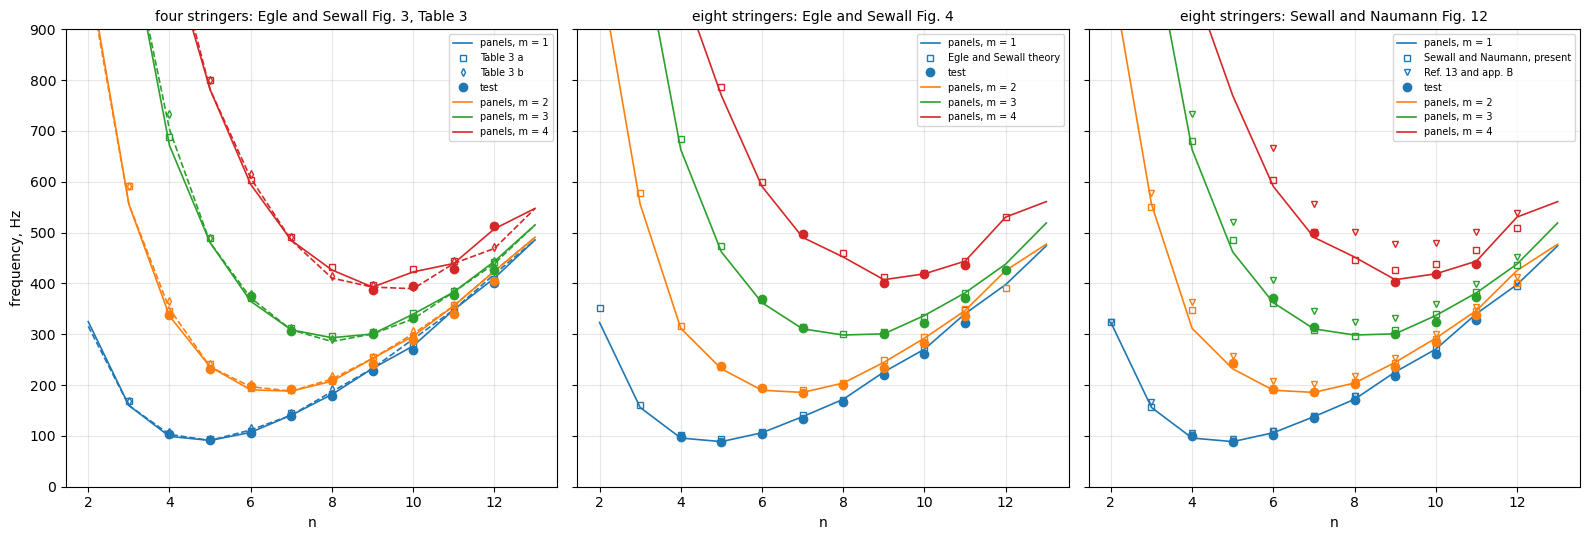

In [15]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5.5), sharey=True)
ns_plot = np.arange(2, 14)
for ax, shell, title in zip(axes, (4, 8, 8), ('four stringers: Egle and Sewall Fig. 3, Table 3',
                                              'eight stringers: Egle and Sewall Fig. 4',
                                              'eight stringers: Sewall and Naumann Fig. 12')):
    for m in range(1, 5):
        col = 'C%d' % (m - 1)
        for sym, ls in (('sym', '-'), ('antisym', '--')):
            if shell == 8 and sym == 'antisym':
                continue
            low = LOW[shell][sym]
            ns = [n for n in ns_plot if (m, n) in low]
            ax.plot(ns, [low[(m, n)]['f'] for n in ns], ls, color=col, lw=1.2,
                    label='panels, m = %d' % m if sym == 'sym' else None)
        if ax is axes[0]:
            for c, mk in (('a', 's'), ('b', 'd')):
                ax.plot(range(3, 13), [TABLE_3[(c, m, n)] for n in range(3, 13)], mk, color=col, ms=4, mfc='none',
                        label='Table 3 %s' % c if m == 1 else None)
        elif ax is axes[1]:
            th = FIGS[('fig4', 'theory', 'sym')]
            pts = sorted(mn for mn in th if mn[0] == m)
            ax.plot([n for _, n in pts], [th[mn] for mn in pts], 's', color=col, ms=4, mfc='none',
                    label='Egle and Sewall theory' if m == 1 else None)
        else:
            for kind, mk, lab in (('present', 's', 'Sewall and Naumann, present'), ('ref13', 'v', 'Ref. 13 and app. B')):
                th = FIGS[('fig12', kind)]
                pts = sorted(mn for mn in th if mn[0] == m)
                ax.plot([n for _, n in pts], [th[mn] for mn in pts], mk, color=col, ms=4, mfc='none',
                        label=lab if m == 1 else None)
    ax.set_ylim(0, 900)
    ax.set_xlabel('n')
    ax.set_title(title, fontsize=10)
    ax.grid(alpha=0.3)
    ax.legend(fontsize=7)
axes[0].set_ylabel('frequency, Hz')
plt.tight_layout()
plt.show()

## Mode shapes and circumferential coupling

Egle and Sewall plot the normal displacement $w$ around the circumference for four symmetric modes of each shell (Figs. 5 and 6, p. 524, at an arbitrary section) and give the ratio of the second largest to the largest amplitude of the harmonics (p. 524-525): four stringers, $(m, n) = (1, 4)$: 0.0618, $(1, 8)$: 0.194, $(2, 9)$: 0.720 (the fifth harmonic on the ninth), $(2, 15)$: 0.247 (the third on the fifteenth); eight stringers, $(1, 4)$: 0.0178, $(1, 8)$: 0.00228. Their frequencies are printed in the figures: Fig. 5, 102.8, 183.0, 256.5 and 659.0 cps; Fig. 6, 98.9, 170.3, 475.1 ($m = 1$, $n = 13$) and 475.7 cps ($m = 2$, $n = 13$). The table compares the same symmetric modes of `panels`, with and without the in-surface inertia of the skin, and the figure shows $w(\theta)$ at the section of largest $|w|$ of each mode of `panels` (normalized), with the stringers marked.

| stringers | m, n | Egle and Sewall, cps | panels | panels, no in-surface inertia | coupling, Egle and Sewall | coupling, panels | coupling, no in-surface inertia |
|---|---|---|---|---|---|---|---|
| 4 | 1, 4 | 102.8 | 99.0 (-3.7%) | 101.7 (-1.0%) | 0.0618 | 0.0463 | 0.0503 |
| 4 | 1, 8 | 183.0 | 181.5 (-0.8%) | 182.9 (-0.0%) | 0.194 | 0.166 | 0.178 |
| 4 | 2, 9 | 256.5 | 252.4 (-1.6%) | 255.0 (-0.6%) | 0.72 | 0.541 | 0.674 |
| 4 | 2, 15 | 659.0 | 656.8 (-0.3%) | 661.0 (+0.3%) | 0.247 | 0.232 | 0.349 |
| 8 | 1, 4 | 98.9 | 95.8 (-3.1%) | 98.2 (-0.8%) | 0.0178 | 0.0101 | 0.0108 |
| 8 | 1, 8 | 170.3 | 172.1 (+1.0%) | 173.1 (+1.7%) | 0.00228 | 0.00235 | 0.00232 |
| 8 | 1, 13 | 475.1 | 474.1 (-0.2%) | 475.6 (+0.1%) | - | 0.13 | 0.134 |
| 8 | 2, 13 | 475.7 | 477.2 (+0.3%) | 479.7 (+0.8%) | - | 0.235 | 0.192 |

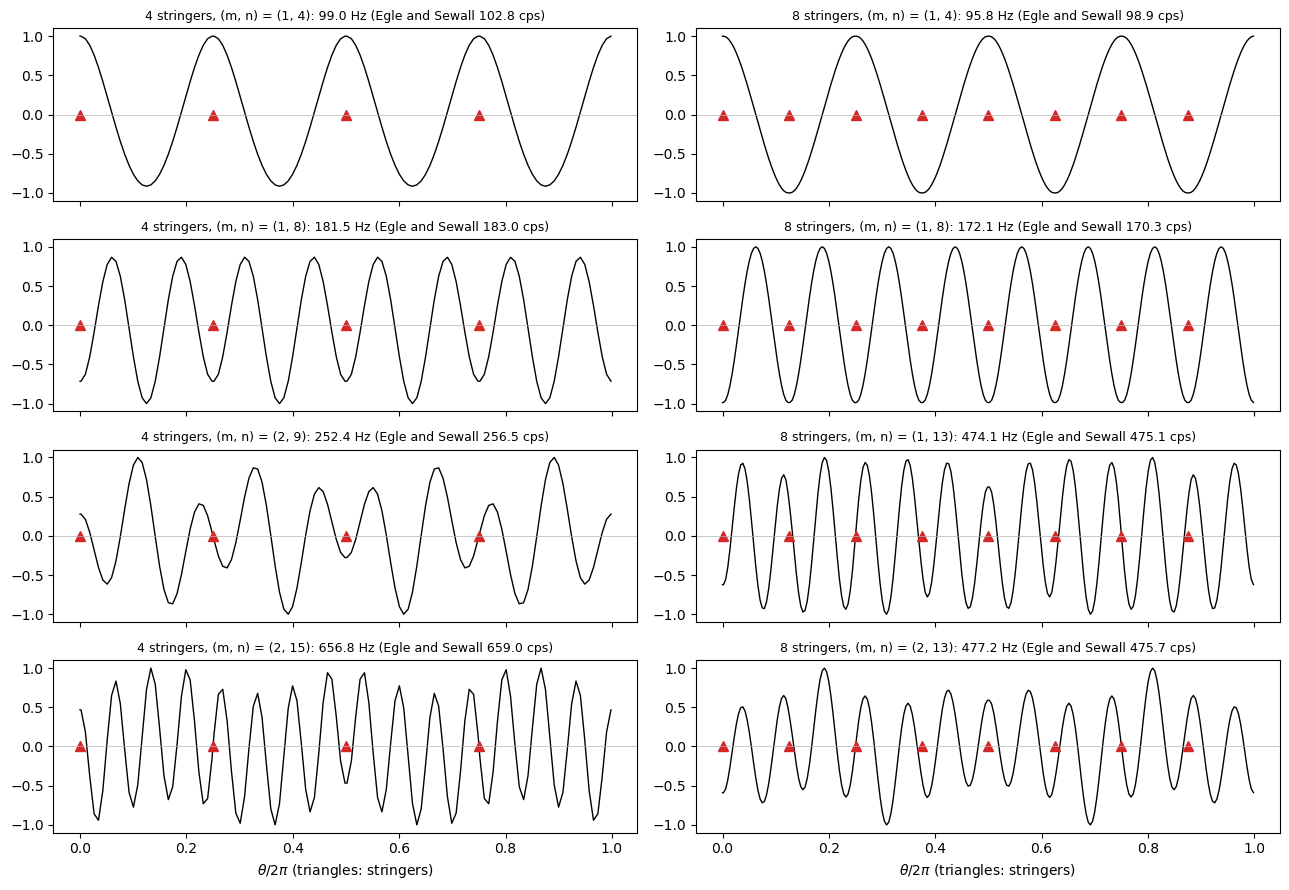

In [16]:
FIG56 = {4: [((1, 4), 102.8, 0.0618), ((1, 8), 183.0, 0.194), ((2, 9), 256.5, 0.720), ((2, 15), 659.0, 0.247)],
         8: [((1, 4), 98.9, 0.0178), ((1, 8), 170.3, 0.00228), ((1, 13), 475.1, None), ((2, 13), 475.7, None)]}


def find_sym(modes, mn):
    for mode in modes:
        if mode['sym'] > 0.9 and (mode['m'], mode['n']) == mn:
            return mode
    return None


rows = []
for shell in (4, 8):
    for mn, fref, rref in FIG56[shell]:
        mode = find_sym(RES[(shell, FINAL)]['modes'], mn)
        mode0 = find_sym(RES_NI[shell]['modes'], mn)
        rows.append(['%d' % shell, '%d, %d' % mn, '%.1f' % fref,
                     '%.1f (%+.1f%%)' % (mode['f'], pct(mode['f'], fref)) if mode else 'not found',
                     '%.1f (%+.1f%%)' % (mode0['f'], pct(mode0['f'], fref)) if mode0 else 'not found',
                     '%g' % rref if rref else '-', '%.3g' % mode['ratio'] if mode else '',
                     '%.3g' % mode0['ratio'] if mode0 else ''])
display(markdown_table(['stringers', 'm, n', 'Egle and Sewall, cps', 'panels', 'panels, no in-surface inertia',
                        'coupling, Egle and Sewall', 'coupling, panels', 'coupling, no in-surface inertia'], rows))

fig, axes = plt.subplots(4, 2, figsize=(13, 9), sharex=True)
for j, shell in enumerate((4, 8)):
    res = RES[(shell, FINAL)]
    for i, (mn, fref, rref) in enumerate(FIG56[shell]):
        ax = axes[i, j]
        mode = find_sym(res['modes'], mn)
        if mode is None:
            ax.set_title('%d stringers, (m, n) = (%d, %d): not found' % ((shell,) + mn), fontsize=9)
            continue
        x, th, w = fu.skin_w(res['md'], mode['c'], res['skin'], R, res['th0'])
        k = np.argmax(np.abs(w).max(axis=0))
        wk = w[:, k]/np.abs(w[:, k]).max()
        thn = np.mod(th, 2*np.pi)/(2*np.pi)
        o = np.argsort(thn)
        ax.plot(thn[o], wk[o], 'k-', lw=1)
        ax.plot(np.arange(shell)/shell, np.zeros(shell), 'C3^', ms=7)
        ax.axhline(0, color='0.7', lw=0.5)
        ax.set_title('%d stringers, (m, n) = (%d, %d): %.1f Hz (Egle and Sewall %.1f cps)'
                     % ((shell,) + mn + (mode['f'], fref)), fontsize=9)
        ax.set_ylim(-1.1, 1.1)
for ax in axes[-1]:
    ax.set_xlabel(r'$\theta/2\pi$ (triangles: stringers)')
plt.tight_layout()
plt.show()

The unrolled skin of the lowest symmetric and antisymmetric modes with $n = 4$ and $m = 1$ of the four-stringer shell, where the stringers lie at the antinodes (symmetric) or at the nodes (antisymmetric) of $w$ (Egle and Sewall, p. 523), and of the lowest mode of each shell.

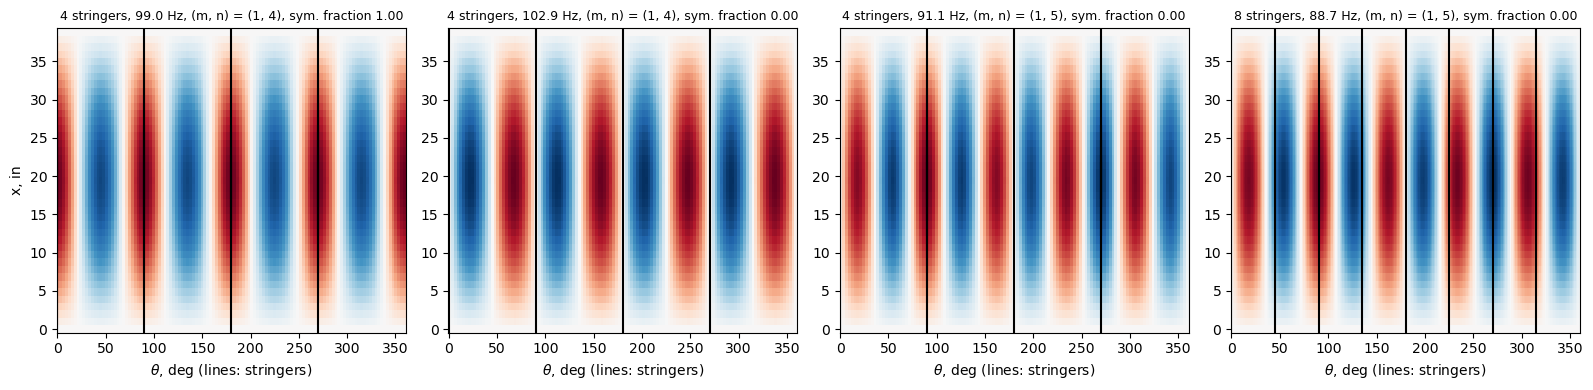

In [17]:
def lowest_mode(modes, sym=None, mn=None):
    for mode in modes:
        if sym == 'sym' and mode['sym'] < 0.9:
            continue
        if sym == 'antisym' and mode['sym'] > 0.1:
            continue
        if mn is None or (mode['m'], mode['n']) == mn:
            return mode


cases = [(4, 'sym', (1, 4)), (4, 'antisym', (1, 4)), (4, None, None), (8, None, None)]
fig, axes = plt.subplots(1, 4, figsize=(16, 4))
for ax, (shell, sym, mn) in zip(axes, cases):
    res = RES[(shell, FINAL)]
    mode = lowest_mode(res['modes'], sym, mn)
    x, th, w = fu.skin_w(res['md'], mode['c'], res['skin'], R, res['th0'])
    o = np.argsort(np.mod(th, 2*np.pi))
    ax.pcolormesh(np.degrees(np.mod(th, 2*np.pi))[o], x/IN, (w[o]/np.abs(w).max()).T, cmap='RdBu_r',
                  shading='auto', vmin=-1, vmax=1)
    for k in range(shell):
        ax.axvline(360*k/shell, color='k', lw=1.5)
    ax.set_title('%d stringers, %.1f Hz, (m, n) = (%d, %d), sym. fraction %.2f'
                 % (shell, mode['f'], mode['m'], mode['n'], mode['sym']), fontsize=9)
    ax.set_xlabel(r'$\theta$, deg (lines: stringers)')
axes[0].set_ylabel('x, in')
plt.tight_layout()
plt.show()

## Sensitivity to the section idealisation

The reference model is compared with the two variants of the section described above, at the last step of the convergence study: the base in the laminate of the skin strip, and the height 0.394 in read from the outer face of the base. The table gives the mean, smallest and largest relative difference of the variant against the reference model over $m$ = 1 to 4, $n$ = 3 to 12, both symmetries.

In [18]:
RES_VAR = {}
rows = []
outliers = []
for shell in (4, 8):
    for name, kw in (('base in the skin laminate', dict(base='laminate')),
                     ('height from the outer face of the base', dict(sec=SEC_OUTER))):
        res = run(shell, LEVELS[shell][FINAL], **kw)
        RES_VAR[(shell, name)] = res['low']
        d = []
        for s in ('sym', 'antisym'):
            for m in range(1, 5):
                for n in range(3, 13):
                    if (m, n) in res['low'][s] and (m, n) in LOW[shell][s]:
                        f1, f0 = res['low'][s][(m, n)]['f'], LOW[shell][s][(m, n)]['f']
                        d.append(pct(f1, f0))
                        if abs(d[-1]) > 2:
                            outliers.append(['%d' % shell, name, s, '%d, %d' % (m, n), '%.1f' % f0, '%.1f' % f1,
                                             '%.2f, %.2f' % (LOW[shell][s][(m, n)]['sym'], res['low'][s][(m, n)]['sym'])])
        rows.append(['%d' % shell, name] + stats(d))
display(markdown_table(['stringers', 'variant against the reference model'] + STATS, rows))
if outliers:
    display(Markdown('Differences above 2 %:'))
    display(markdown_table(['stringers', 'variant', 'symmetry', 'm, n', 'reference, Hz', 'variant, Hz',
                            'sym. fraction (reference, variant)'], outliers))

| stringers | variant against the reference model | values | mean | mean abs. | min. | max. |
|---|---|---|---|---|---|---|
| 4 | base in the skin laminate | 80 | -0.1% | 0.1% | -0.2% | +0.0% |
| 4 | height from the outer face of the base | 80 | -0.0% | 0.1% | -0.9% | +0.3% |
| 8 | base in the skin laminate | 80 | -0.0% | 0.2% | -0.4% | +8.1% |
| 8 | height from the outer face of the base | 80 | -0.0% | 0.3% | -1.2% | +0.9% |

Differences above 2 %:

| stringers | variant | symmetry | m, n | reference, Hz | variant, Hz | sym. fraction (reference, variant) |
|---|---|---|---|---|---|---|
| 8 | base in the skin laminate | antisym | 4, 4 | 1051.9 | 1137.3 | 0.00, 0.00 |

| tests | variant, symmetric modes | values | mean | mean abs. | min. | max. |
|---|---|---|---|---|---|---|
| tests of Fig. 3 | base in the skin laminate | 27 | +1.2% | 2.4% | -4.9% | +6.7% |
| tests of Fig. 3 | height from the outer face of the base | 27 | +1.1% | 2.4% | -4.7% | +6.1% |
| tests of Fig. 4 | base in the skin laminate | 25 | +1.5% | 2.3% | -2.3% | +5.4% |
| tests of Fig. 4 | height from the outer face of the base | 25 | +1.5% | 2.4% | -2.1% | +5.7% |
| tests of Fig. 12 | base in the skin laminate | 24 | +0.8% | 2.1% | -4.6% | +4.1% |
| tests of Fig. 12 | height from the outer face of the base | 24 | +0.8% | 2.3% | -4.5% | +4.2% |

### Section scaled to the area of Table 1

The section of the drawing has 1.6 % more area than $A_s$ of Table 1 (the section table above). In this variant the wall thickness $t$ of the channel is scaled, the outer dimensions of the drawing kept, until the area of the plates (`fu.section_properties`, base as a plate) equals $A_s$ = 1.627e-2 in$^2$; the other properties follow. The model is solved at the last step of the convergence study, with and without the in-surface inertia of the skin, and compared with the reference model (the drawn section) and with Table 3.

In [19]:
from scipy.optimize import brentq


def channel_t(t_in):
    return fu.channel_midlines(t_in*IN, 0.197*IN, 0.394*IN, 0.098*IN)


T_A = brentq(lambda t_in: fu.section_properties(channel_t(t_in), H)['A']/IN**2 - TABLE_1['A'], 0.010, 0.016)
SEC_A = channel_t(T_A)
rows = [['Table 1 (p. 522)', '-', '%.4e' % TABLE_1['A'], '%.4f' % abs(TABLE_1['z']), '%.4f' % TABLE_1['d'],
         '%.4f' % TABLE_1['p'], '%.2f' % TABLE_1['GJ']]]
for label, sec in (('drawing (reference model)', SEC), ('scaled to A of Table 1', SEC_A)):
    sp = fu.section_properties(sec, H)
    A, z, d, p, GJ = sp['A']/IN**2, sp['z']/IN, sp['d']/IN, sp['p']/IN, G_PSI*sp['J']/IN**4
    rows.append([label, '%.5f' % (sec['t']/IN), '%.4e (%+.1f%%)' % (A, pct(A, TABLE_1['A'])),
                 '%.4f (%+.1f%%)' % (z, pct(z, abs(TABLE_1['z']))), '%.4f (%+.1f%%)' % (d, pct(d, TABLE_1['d'])),
                 '%.4f (%+.1f%%)' % (p, pct(p, TABLE_1['p'])), '%.2f (%+.1f%%)' % (GJ, pct(GJ, TABLE_1['GJ']))])
display(markdown_table(['section', 't, in', 'A, in^2', 'centroid inside the skin middle surface, in', "d', in",
                        "p', in", 'GJ, lb-in^2'], rows))
LOW_A = {shell: run(shell, LEVELS[shell][FINAL], sec=SEC_A)['low'] for shell in (4, 8)}
LOW_A_NI = {shell: run(shell, LEVELS[shell][FINAL], sec=SEC_A, no_skin_inplane_inertia=True)['low']
            for shell in (4, 8)}


def against(low, ref_low):
    return [pct(low[s][mn]['f'], ref_low[s][mn]['f']) for s in ('sym', 'antisym') for m in range(1, 5)
            for n in range(3, 13) for mn in [(m, n)] if mn in low[s] and mn in ref_low[s]]


rows = []
for shell in (4, 8):
    rows.append(['%d' % shell, 'with'] + stats(against(LOW_A[shell], LOW[shell])))
    rows.append(['%d' % shell, 'without'] + stats(against(LOW_A_NI[shell], LOW_NI[shell])))
display(Markdown('Scaled section against the drawn section, the same inertia, $m$ = 1 to 4, $n$ = 3 to 12, '
                 'both symmetries:'))
display(markdown_table(['stringers', 'in-surface inertia of the skin'] + STATS, rows))
rows = []
for col, sym in (('a', 'sym'), ('b', 'antisym')):
    for label, low in (('drawn section', LOW[4]), ('scaled section', LOW_A[4]),
                       ('drawn section, no in-surface inertia', LOW_NI[4]),
                       ('scaled section, no in-surface inertia', LOW_A_NI[4])):
        d = [pct(low[sym][(m, n)]['f'], TABLE_3[(col, m, n)]) for m in range(1, 5) for n in range(3, 13)
             if (m, n) in low[sym]]
        rows.append(['Table 3 %s' % col, label] + stats(d))
display(markdown_table(['reference', 'panels'] + STATS, rows))
rows = []
for m in range(1, 5):
    for n in range(4, 13, 2):
        sa, aa = LOW_A_NI[4]['sym'].get((m, n)), LOW_A_NI[4]['antisym'].get((m, n))
        rows.append(['%d, %d' % (m, n), '%+g' % (TABLE_3[('a', m, n)] - TABLE_3[('b', m, n)]),
                     '%+.1f' % (LOW_NI[4]['sym'][(m, n)]['f'] - LOW_NI[4]['antisym'][(m, n)]['f']),
                     '%+.1f' % (sa['f'] - aa['f']) if sa and aa else 'not found'])
display(Markdown('Splitting of the even $n$, without the in-surface inertia of the skin:'))
display(markdown_table(['m, n', 'Table 3: a - b, Hz', 'drawn section, Hz', 'scaled section, Hz'], rows))

| section | t, in | A, in^2 | centroid inside the skin middle surface, in | d', in | p', in | GJ, lb-in^2 |
|---|---|---|---|---|---|---|
| Table 1 (p. 522) | - | 1.6270e-02 | 0.2082 | 0.2576 | 0.2750 | 11.31 |
| drawing (reference model) | 0.01400 | 1.6534e-02 (+1.6%) | 0.2176 (+4.5%) | 0.2625 (+1.9%) | 0.2807 (+2.1%) | 12.05 (+6.5%) |
| scaled to A of Table 1 | 0.01378 | 1.6270e-02 (+0.0%) | 0.2174 (+4.4%) | 0.2623 (+1.8%) | 0.2806 (+2.0%) | 11.48 (+1.5%) |

Scaled section against the drawn section, the same inertia, $m$ = 1 to 4, $n$ = 3 to 12, both symmetries:

| stringers | in-surface inertia of the skin | values | mean | mean abs. | min. | max. |
|---|---|---|---|---|---|---|
| 4 | with | 80 | +0.0% | 0.0% | -0.1% | +0.1% |
| 4 | without | 80 | +0.0% | 0.0% | -0.1% | +0.1% |
| 8 | with | 80 | +0.0% | 0.1% | -0.1% | +0.2% |
| 8 | without | 80 | +0.0% | 0.1% | -0.1% | +0.2% |

| reference | panels | values | mean | mean abs. | min. | max. |
|---|---|---|---|---|---|---|
| Table 3 a | drawn section | 40 | -1.7% | 1.8% | -5.9% | +0.6% |
| Table 3 a | scaled section | 40 | -1.7% | 1.7% | -5.9% | +0.7% |
| Table 3 a | drawn section, no in-surface inertia | 40 | -0.4% | 0.5% | -2.0% | +1.0% |
| Table 3 a | scaled section, no in-surface inertia | 40 | -0.3% | 0.5% | -2.0% | +1.0% |
| Table 3 b | drawn section | 40 | -2.2% | 2.2% | -5.9% | -0.5% |
| Table 3 b | scaled section | 40 | -2.2% | 2.2% | -5.9% | -0.5% |
| Table 3 b | drawn section, no in-surface inertia | 40 | -0.8% | 0.9% | -2.5% | +0.6% |
| Table 3 b | scaled section, no in-surface inertia | 40 | -0.8% | 0.8% | -2.5% | +0.7% |
| tests of Fig. 3 | drawn section, symmetric modes | 27 | +1.2% | 2.4% | -4.9% | +6.8% |
| tests of Fig. 3 | scaled section, symmetric modes | 27 | +1.3% | 2.4% | -4.8% | +6.7% |
| tests of Fig. 4 | drawn section, symmetric modes | 25 | +1.6% | 2.4% | -2.2% | +5.6% |
| tests of Fig. 4 | scaled section, symmetric modes | 25 | +1.7% | 2.4% | -2.1% | +5.6% |
| tests of Fig. 12 | drawn section, symmetric modes | 24 | +0.9% | 2.2% | -4.6% | +4.2% |
| tests of Fig. 12 | scaled section, symmetric modes | 24 | +1.0% | 2.2% | -4.5% | +4.3% |

Splitting of the even $n$, without the in-surface inertia of the skin:

| m, n | Table 3: a - b, Hz | drawn section, Hz | scaled section, Hz |
|---|---|---|---|
| 1, 4 | -5 | -4.3 | -4.3 |
| 1, 6 | -7 | -5.0 | -4.9 |
| 1, 8 | -9 | -5.7 | -5.6 |
| 1, 10 | -19 | -12.0 | -11.8 |
| 1, 12 | -17 | -7.6 | -7.5 |
| 2, 4 | -19 | -16.6 | -16.4 |
| 2, 6 | -8 | -6.6 | -6.5 |
| 2, 8 | -8 | -4.5 | -4.4 |
| 2, 10 | -9 | -4.6 | -4.5 |
| 2, 12 | -6 | +0.8 | +0.7 |
| 3, 4 | -45 | -36.4 | -36.0 |
| 3, 6 | -8 | -7.3 | -7.2 |
| 3, 8 | +7 | +7.3 | +7.3 |
| 3, 10 | +7 | +9.3 | +9.2 |
| 3, 12 | -1 | +4.4 | +4.5 |
| 4, 4 | -55 | -31.8 | -31.3 |
| 4, 6 | -11 | -11.2 | -11.1 |
| 4, 8 | +17 | +15.8 | +15.7 |
| 4, 10 | +35 | +33.1 | +32.8 |
| 4, 12 | +41 | +38.7 | +38.4 |

## Discussion

- **Convergence.** In the last step the compared frequencies change by at most 0.03 % (four stringers) and less than 0.01 % (eight stringers, unstiffened shell). The eigenpairs have backward errors of $10^{-11}$ or less; their relative residuals reach $10^{-1}$ because the matrices reduced by the null-space method are ill-conditioned, not because the eigenpairs are inaccurate.
- **Unstiffened shell and in-surface inertia.** Column c of Table 3 is the Donnell frequency without in-surface inertia (closed form within 0.3 %). `panels`, with the inertia of all displacements, is 2.3 % below it on average and 4.4 % below at $n$ = 3 and 4; with the in-surface inertia of the skin removed the mean difference falls to $-0.7$ % ($-2.5$ to 0.0 %). The remainder is the difference between the Sanders-Koiter kinematics of the model and Donnell's: the circumferential bending term $(\lambda^2 + n^2)^2$ of Donnell becomes approximately $(\lambda^2 + n^2 - 1)^2$, which lowers the frequency where bending dominates, e.g. by 2.3 % at $m = 1$, $n = 5$ (estimate, derived from the closed form), against $-2.4$ % in the table.
- **Four stringers, Table 3.** `panels` is below Table 3 by 1.7 % (symmetric), 2.2 % (antisymmetric) and 2.3 % (unstiffened) on average, by 3.8 to 4.5 % at $n$ = 3 and 4 and by 0.9 to 1.5 % for $n \ge 7$: the stiffened shells follow the unstiffened one, so the difference is that of the in-surface inertia neglected by Egle and Sewall ("the frequencies for low values of $n$ should be expected to be somewhat higher than the correct values", p. 522) and of the shell kinematics. Without the in-surface inertia of the skin, `panels` agrees with columns a and b within $-0.4$ % and $-0.8$ % on average (largest $-2.5$ %, antisymmetric $m = 4$, $n = 4$). The equal frequencies of odd $n$ and the splitting of even $n$ are reproduced: symmetric below antisymmetric for $m$ = 1, 2 and at $n$ = 4, 6 for all $m$, above for $m$ = 3, 4 and $n \ge 8$ (except $m = 3$, $n = 12$, where Table 3 has $-1$ Hz and `panels` $+4.4$ Hz). The splitting of `panels` is smaller where it is large in Table 3 ($m = 1$, $n$ = 10, 12: $-12.0$ and $-7.6$ Hz against $-19$ and $-17$ Hz; $m = 4$, $n = 4$: $-31.8$ against $-55$ Hz), because the antisymmetric frequencies are lower (1115.2 against 1144 Hz at $m = 4$, $n = 4$), the symmetric ones agreeing (1083.4 against 1089 Hz).
- **The splitting and the inertia of the stringers.** The recomputed analysis of Egle and Sewall identifies the cause. With their Eq. (8) as printed, whose kinetic energy of the stringers contains the translation $\dot{v}$ along the circumference with the skin, the recomputed antisymmetric frequencies fall below Table 3 like those of `panels` (1105.6 Hz at $m = 4$, $n = 4$, $-3.4$ %; mean $-0.8$ %). With $\dot{u}$ and $\dot{v}$ also dropped from Eq. (8), the recomputation reproduces column a within $-0.8$ to $+0.4$ % (mean $-0.2$ %), column b within $-0.9$ to $+0.9$ % (mean $-0.2$ %) and column c within $-0.2$ to $+0.3$ %. Egle and Sewall therefore most probably neglected the in-surface inertia of the stringers as well (their "in-surface inertias", p. 522), which removes from the antisymmetric modes, where the stringers lie at the nodes of $w$ and move with the largest $v$ of the skin, most of the inertia of the stringers; this is an inference from the recomputation, which their paper does not state. `panels`, like Eq. (8) as printed, keeps that inertia. The number of terms does not explain the difference: without the in-surface inertia of the stringers 20 and 40 terms differ by 0.16 % at most; with Eq. (8) as printed the 20-term series is less converged (up to 4.8 %), but with 40 terms its antisymmetric frequencies remain below Table 3 (mean $-0.7$ %, down to $-2.2$ %, computed in the bfsccylinder implementation of this case with the same function). Nor does the plate model of the hat: bfsccylinder, with plate elements and the base as a layer of the skin, gives the same splitting (1083.5 / 1114.0 Hz at $m = 4$, $n = 4$ without the in-surface inertia of the skin, against 1083.4 / 1115.2 Hz here), and the section scaled to the area of Table 1 changes it by 0.5 Hz at most.
- **Mode coupling and classification.** The modes of `panels` classified by their dominant harmonic and symmetry are the modes of Egle and Sewall: the modes of Figs. 5 and 6 are found with the printed frequencies within $-3.7$ to $+1.0$ % ($-1.0$ to $+1.7$ % without the in-surface inertia), with the same pattern (stringers at the antinodes of the symmetric even modes, the fifth harmonic strong in the mode $m = 2$, $n = 9$, the third in $m = 2$, $n = 15$). The coupling ratios are of the same size but mostly smaller: four stringers 0.046 against 0.0618, 0.166 against 0.194, 0.54 (0.67 without in-surface inertia) against 0.720, 0.23 (0.35) against 0.247; eight stringers 0.010 against 0.0178 and 0.00235 against 0.00228. Egle and Sewall relate the coupling strength to the closeness of the frequencies of the coupled harmonics (p. 525), which the in-surface inertia changes at low $n$; their ratio is that of the coefficients of a 20-term series, ours that of the Fourier coefficients of the computed $w$ of the skin. Where a mode is strongly coupled, its classification by the dominant harmonic is a convention, and the papers and `panels` may label a mode differently: the curves $m = 1$ and $m = 2$ of Egle and Sewall's Fig. 4 cross near $n = 11$ (reading notes of the CSV file), and the digitised $m = 2$, $n = 12$ value, 390.8 Hz, is 8.9 % below `panels` (425.5 Hz), whereas $m = 1$, $n = 12$ of `panels` is 397.8 Hz.
- **Averaged analyses of Fig. 12.** `panels` is 1.2 % below Sewall and Naumann's averaged analysis with eccentricity on average ($-10.2$ to $+6.0$ %) and 6.4 % below the equivalent shell of Ref. 13 ($-14.6$ to $+3.3$ %), which "does not explicitly account for stiffener eccentricity" (p. 20) and is the highest of the analyses for $m$ = 3, 4; Sewall and Naumann conclude from the same comparison that the eccentricity effect is considerably smaller for this shell than for their integrally stiffened shells (p. 20). Averaged analyses cannot split the frequencies of a pair: the largest differences with the averaged curve are at the even $n$ where the discrete stringers split them (e.g. $m = 2$, $n = 4$: 311.6 Hz symmetric, 346.9 Hz antisymmetric, against 347.0 Hz).
- **Section idealisation and base attachment.** The section drawn in Fig. 12 has 1.6 % more area, a centroid 4.5 % farther from the skin, $d'$ and $p'$ about 2 % larger and a torsion constant 6.5 % larger than Table 1; reading the height from the outer face of the base matches Table 1 better (area $-0.8$ %, centroid +1.1 %) but contradicts the dimension line. Both readings, and the base as part of the skin laminate instead of a bonded plate, change the frequencies by 0.1 to 0.3 % on average; the single larger difference, +8.1 % for the antisymmetric $(m, n) = (4, 4)$ of eight stringers with the base in the laminate (1137.3 against 1051.9 Hz, a value no paper gives), is the only one above 2 %; whether the same mode changed or another mode took the label (4, 4) was not investigated. With the wall thickness scaled to the area of Table 1 (0.01378 in instead of 0.014 in, the outer dimensions kept), the frequencies change by $-0.1$ to $+0.2$ % (mean 0.0 %, both shells, with and without the in-surface inertia of the skin), the mean differences with Table 3 by 0.1 percentage point at most, and the splitting of the even $n$ by 0.5 Hz at most: the area of the stringer does not explain the differences with Egle and Sewall. The $\bar{z}_s$ of Table 1 is probably measured from the inner surface of the skin (see the stringer section above); recomputed with $|\bar{z}_s| + h/2$, the analysis of Egle and Sewall changes by 0.2 percentage points or less in the mean. The corner radii of the formed section and the way the stringers are fastened are not given in the two papers.
- **The other implementation.** The bfsccylinder implementation of the few-stringer shells is compared in the last section; the 60-stringer shell of Egle and Sewall (Table 2) is the ES shell of the notebook [sewall1968_blade_cylinder_vibration](sewall1968_blade_cylinder_vibration.ipynb).

## References

- Egle, D. M., and Sewall, J. L., An analysis of free vibration of orthogonally stiffened cylindrical shells with stiffeners treated as discrete elements, AIAA Journal 6(3) (1968) 518-526, https://doi.org/10.2514/3.4528.
- Sewall, J. L., and Naumann, E. C., An experimental and analytical vibration study of thin cylindrical shells with and without longitudinal stiffeners, NASA TN D-4705, 1968.
- Castro, S. G. P., and Donadon, M. V., Assembly of semi-analytical models to address linear buckling and vibration of stiffened composite panels with debonding defect, Composite Structures 160 (2017) 232-247, https://doi.org/10.1016/j.compstruct.2016.10.026.

## The bfsccylinder implementation of this case

The bfsccylinder implementation of this case (the notebook `egle1968_few_stringer_cylinder_frequencies`
of bfsccylinder: one stringer pitch with cyclic symmetry, the base of the channel as a second layer
of the skin elements under it, webs and lips as plate elements) gives the following mean (min, max)
differences (this notebook in brackets):

| reference | bfsccylinder | panels |
|---|---|---|
| Table 3 a, symmetric | −1.5 % (−5.9, +0.6) | −1.7 % (−5.9, +0.6) |
| Table 3 b, antisymmetric | −2.0 % (−5.9, −0.3) | −2.2 % (−5.9, −0.5) |
| Table 3 c, unstiffened | −2.1 % (−5.6, −0.6) | −2.3 % (−5.7, −0.9) |
| Table 3 a/b/c, no in-surface inertia of the skin | −0.1 / −0.6 / −0.5 % | −0.4 / −0.8 / −0.7 % |
| Fig. 12, "Present paper" curve | −1.0 % (−5.1, +5.1) | −1.2 % (−10.2, +6.0) |
| Fig. 12, "Ref. 13 and app. B" curve | −6.2 % (−14.3, +2.4) | −6.4 % (−14.6, +3.3) |

The two implementations agree within 0.3 percentage points on average, and both find the outlier
at $(m, n) = (2, 12)$ of Fig. 4 (+9.0 % and +8.9 %), where the $m = 1$ and $m = 2$ curves cross.
The section of the bfsccylinder model has 4.4 % more area than Table 1 (its webs overlap the
skin and the base), against +1.6 % here; scaled to the area of Table 1 (wall thickness 0.01342 in
there, 0.01378 in here) the frequencies change by −0.2 to +0.6 % there and −0.1 to +0.2 % here.
The splitting of the symmetric and antisymmetric frequencies at even $n$ is the same in both, and
smaller than in Table 3 where Table 3 splits most: without the in-surface inertia of the skin, at
$m = 4$, $n = 4$, 1083.5 / 1114.0 Hz in bfsccylinder and 1083.4 / 1115.2 Hz here, against 1089 /
1144 Hz. Both notebooks recompute the analysis of Egle and Sewall with the same function and find
that Table 3 is reproduced only with the in-surface inertia of the stringers neglected too (see the
discussion above).